# Cricket Multi-Dataset Statistical & Relationship Analysis

**A step-by-step Jupyter Notebook for all six uploaded CSV datasets**

This notebook studies the six related cricket datasets together. It checks the source tables, discovers their keys, verifies relationships, joins related information, measures statistical relationships, creates cricket-specific summaries, and exports tables and charts.

## Datasets used

1. `playing_eleven.csv`
2. `ball_by_ball(1).csv` (the uploaded `ball_by_ball.csv` is an identical copy; either filename can be used)
3. `competition_team_player_mapping.csv`
4. `competitions.csv`
5. `matches.csv`
6. `teams.csv`

## How to use this notebook

- Put this notebook in the same folder as the six CSV files, or edit `DATA_DIR` in Step 1.
- Run the cells from top to bottom using **Kernel → Restart Kernel and Run All**.
- The notebook does not change the original CSV files. It writes derived tables and charts into `cricket_analysis_outputs/`.
- Install the required libraries first if necessary: `pip install pandas numpy matplotlib scipy`.

> **Interpretation note:** Correlation describes association, not causation. Some correlations (for example, runs with four/six flags) are expected because the fields describe the same delivery event. The dataset has repeated lineup keys and some unusual bowling-speed values; these are reported instead of silently corrected.

## How this notebook is organised

| Part | Steps | Purpose |
|---|---|---|
| **A. Understand the data** | 1 to 36 | Load the six tables, check keys and relationships, profile every column, explore patterns. *(unchanged)* |
| **B. Solve the Round-1 problem** | 37 to 52 | Define **pressure**, measure batters and bowlers under pressure against their usual level, rank the most reliable players, and test how trustworthy the ranking is. |

Part B reuses the tables that Part A loads (`ball`, `matches`, `competitions`, `mapping`), so run the notebook from the top.


## Step 1 — Import libraries and set file locations

We use pandas for table operations, NumPy for numerical calculations, and Matplotlib for visualizations. Change `DATA_DIR` only when your CSV files are stored somewhere else.

In [3]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Folder containing the six original CSV files.
DATA_DIR = Path.home() / "OneDrive" / "Desktop" / "RR" / "Data Pack"
OUTPUT_DIR = DATA_DIR / "cricket_analysis_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Use the uploaded ball_by_ball(1).csv by default.
# If you only have ball_by_ball.csv, the notebook will use that instead.
BALL_FILE_CANDIDATES = ["ball_by_ball(1).csv", "ball_by_ball.csv"]

print("Input folder:", DATA_DIR)
print("Output folder:", OUTPUT_DIR)

Input folder: C:\Users\LENOVO\OneDrive\Desktop\RR\Data Pack
Output folder: C:\Users\LENOVO\OneDrive\Desktop\RR\Data Pack\cricket_analysis_outputs


## Step 2 — Load the six datasets

Each CSV is loaded into a named pandas DataFrame. The helper function checks that each required file exists and gives a readable error if one is missing.

In [4]:
def choose_existing_file(candidates, folder=DATA_DIR):
    for filename in candidates:
        path = folder / filename
        if path.exists():
            return path
    raise FileNotFoundError(
        f"Could not find any of these files in {folder}: {candidates}"
    )

file_paths = {
    "playing_eleven": DATA_DIR / "playing_eleven.csv",
    "ball_by_ball": choose_existing_file(BALL_FILE_CANDIDATES),
    "player_mapping": DATA_DIR / "competition_team_player_mapping.csv",
    "competitions": DATA_DIR / "competitions.csv",
    "matches": DATA_DIR / "matches.csv",
    "teams": DATA_DIR / "teams.csv",
}

missing_paths = [str(p) for p in file_paths.values() if not p.exists()]
if missing_paths:
    raise FileNotFoundError("Missing required file(s):\n" + "\n".join(missing_paths))

data = {name: pd.read_csv(path) for name, path in file_paths.items()}
pe = data["playing_eleven"]
ball = data["ball_by_ball"]
mapping = data["player_mapping"]
competitions = data["competitions"]
matches = data["matches"]
teams = data["teams"]

print("Loaded all datasets successfully.")
for name, path in file_paths.items():
    print(f"{name:16s} -> {path.name}")

Loaded all datasets successfully.
playing_eleven   -> playing_eleven.csv
ball_by_ball     -> ball_by_ball.csv
player_mapping   -> competition_team_player_mapping.csv
competitions     -> competitions.csv
matches          -> matches.csv
teams            -> teams.csv


## Step 3 — Dataset dimensions and memory usage

Rows are observations and columns are attributes. Memory usage is an estimate of the memory occupied by each DataFrame after loading.

In [5]:
overview_rows = []
for name, df in data.items():
    overview_rows.append({
        "dataset": name,
        "file": file_paths[name].name,
        "rows": len(df),
        "columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum()),
        "full_duplicate_rows": int(df.duplicated().sum()),
        "memory_MB": df.memory_usage(deep=True).sum() / (1024 ** 2),
    })

dataset_overview = pd.DataFrame(overview_rows)
display(dataset_overview)

,dataset,file,rows,columns,missing_cells,full_duplicate_rows,memory_MB
0,playing_eleven,playing_eleven.csv,28381,9,26012,0,3.209
1,ball_by_ball,ball_by_ball.csv,200999,33,766466,0,165.277
2,player_mapping,competition_team_player_mapping.csv,6413,6,0,0,1.388
3,competitions,competitions.csv,141,4,0,0,0.027
4,matches,matches.csv,883,22,2736,0,0.462
5,teams,teams.csv,353,3,0,0,0.026


## Step 4 — Inspect the structure of every dataset

`head()` shows example records, `info()` shows data types and non-missing counts, and `describe()` summarizes numerical and categorical columns. Run the cell to inspect all six tables.

In [6]:
for name, df in data.items():
    print("\\n" + "=" * 100)
    print(f"DATASET: {name.upper()} | SHAPE: {df.shape}")
    display(df.head(5))
    print("Data types and non-null counts:")
    df.info()
    print("Descriptive summary:")
    display(df.describe(include="all").T)

\n====================================================================================================
DATASET: PLAYING_ELEVEN | SHAPE: (28381, 9)


,match_id,team_id,player_id,batting_order,is_played,is_captain,is_wk,is_impact,is_impact_off
0,13511,22,1187,1.000,True,False,False,0,0
1,13511,22,6273,2.000,True,False,False,0,0
2,13511,22,1210,3.000,True,False,False,0,0
3,13511,22,1596,4.000,True,False,False,0,0
4,13511,22,478,5.000,True,False,False,0,0


Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 28381 entries, 0 to 28380
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   match_id       28381 non-null  int64  
 1   team_id        28381 non-null  int64  
 2   player_id      28381 non-null  int64  
 3   batting_order  19703 non-null  float64
 4   is_played      28381 non-null  bool   
 5   is_captain     19714 non-null  object 
 6   is_wk          19714 non-null  object 
 7   is_impact      28381 non-null  int64  
 8   is_impact_off  28381 non-null  int64  
dtypes: bool(1), float64(1), int64(5), object(2)
memory usage: 1.8+ MB
Descriptive summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
match_id,"28,381.000",NaN,NaN,NaN,"35,614.824","12,100.943","13,511.000","28,066.000","37,928.000","46,251.000","55,561.000"
team_id,"28,381.000",NaN,NaN,NaN,453.408,"1,130.175",1.000,7.000,21.000,72.000,"4,444.000"
player_id,"28,381.000",NaN,NaN,NaN,"9,764.020","12,357.993",8.000,"3,091.000","5,379.000","7,901.000","71,727.000"
batting_order,"19,703.000",NaN,NaN,NaN,6.169,3.276,1.000,3.000,6.000,9.000,13.000
is_played,28381,2,True,19714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_captain,19714,2,False,18031,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_wk,19714,2,False,18039,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_impact,"28,381.000",NaN,NaN,NaN,0.020,0.139,0.000,0.000,0.000,0.000,1.000
is_impact_off,"28,381.000",NaN,NaN,NaN,0.020,0.139,0.000,0.000,0.000,0.000,1.000


\n====================================================================================================
DATASET: BALL_BY_BALL | SHAPE: (200999, 33)


,match_id,innings,overid,over_ball_num,innings_ball_num,batting_team_id,bowling_team_id,striker_id,striker_name,non_striker_id,non_striker_name,bowler_id,bowler_name,batting_type,bowling_type,batting_order,runs,is_four,is_six,is_wicket,dismissal_type_id,dismissal_type,dismissed_player_id,extras_type,extras1_runs,extras_2_runs,pace_or_spin,bowl_speed,stroke,delivery_style,over_or_around,on_or_off,delivery_ist_time
0,13511,1,1,1,1,22,28,1187,Jason Roy,6273,Tom Banton,1772,Sheldon Cottrell,RHB,Left-arm fast-medium,1,0,False,False,False,NaN,NaN,NaN,NaN,0,0,Pace,0.000,Cover Drive,Inswing,Over,Off-side,2022-01-23 00:00:00 UTC
1,13511,1,1,2,2,22,28,1187,Jason Roy,6273,Tom Banton,1772,Sheldon Cottrell,RHB,Left-arm fast-medium,1,0,False,False,False,NaN,NaN,NaN,NaN,0,0,Pace,0.000,Flick,Inswing,Over,On-side,2022-01-23 00:00:00 UTC
2,13511,1,1,3,3,22,28,1187,Jason Roy,6273,Tom Banton,1772,Sheldon Cottrell,RHB,Left-arm fast-medium,1,0,False,False,False,NaN,NaN,NaN,NaN,0,0,Pace,0.000,Square Cut,Inswing,Over,Off-side,2022-01-23 00:00:00 UTC
3,13511,1,1,4,4,22,28,1187,Jason Roy,6273,Tom Banton,1772,Sheldon Cottrell,RHB,Left-arm fast-medium,1,0,False,False,False,NaN,NaN,NaN,NaN,0,0,Pace,0.000,Backfoot defensive,Inswing,Over,On-side,2022-01-23 00:00:00 UTC
4,13511,1,1,5,5,22,28,1187,Jason Roy,6273,Tom Banton,1772,Sheldon Cottrell,RHB,Left-arm fast-medium,1,6,False,True,False,NaN,NaN,NaN,NaN,0,0,Pace,0.000,Pull shot,Seamed In,Over,On-side,2022-01-23 00:00:00 UTC


... (14 outputs left out)

\n====================================================================================================
DATASET: TEAMS | SHAPE: (353, 3)


,comp_id,team_id,team_name
0,1331,22,England
1,1331,28,West Indies
2,1335,18,India
3,1335,28,West Indies
4,1345,20,Australia


Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 353 entries, 0 to 352
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   comp_id    353 non-null    int64
 1   team_id    353 non-null    int64
 2   team_name  353 non-null    str  
dtypes: int64(2), str(1)
memory usage: 8.4 KB
Descriptive summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
comp_id,353.000,NaN,NaN,NaN,"2,466.079",712.954,"1,331.000","1,715.000","2,513.000","3,159.000","3,787.000"
team_id,353.000,NaN,NaN,NaN,221.527,771.150,1.000,18.000,23.000,28.000,"4,444.000"
team_name,353,38,India,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Step 5 — Create a complete profile for every attribute

For every column, calculate data type, non-null count, missing count and percentage, distinct values, mode and (where numeric) minimum, quartiles, median and maximum. This makes it easier to understand all 77 attributes across the six tables.

In [7]:
def profile_one_dataset(dataset_name, df):
    rows = []
    for col in df.columns:
        s = df[col]
        mode_values = s.mode(dropna=True)
        numeric = pd.to_numeric(s, errors="coerce").astype(float)
        is_numeric_like = pd.api.types.is_numeric_dtype(s) or (
            s.notna().sum() > 0 and numeric.notna().sum() >= 0.90 * s.notna().sum()
        )
        rows.append({
            "dataset": dataset_name,
            "attribute": col,
            "dtype": str(s.dtype),
            "non_null": int(s.notna().sum()),
            "missing": int(s.isna().sum()),
            "missing_pct": 100 * s.isna().mean(),
            "distinct_non_null": int(s.nunique(dropna=True)),
            "mode": mode_values.iloc[0] if len(mode_values) else np.nan,
            "mode_count": int((s == mode_values.iloc[0]).sum()) if len(mode_values) else 0,
            "minimum": numeric.min() if is_numeric_like else np.nan,
            "q25": numeric.quantile(.25) if is_numeric_like else np.nan,
            "median": numeric.median() if is_numeric_like else np.nan,
            "q75": numeric.quantile(.75) if is_numeric_like else np.nan,
            "maximum": numeric.max() if is_numeric_like else np.nan,
        })
    return pd.DataFrame(rows)

all_column_profiles = pd.concat(
    [profile_one_dataset(name, df) for name, df in data.items()],
    ignore_index=True
)
display(all_column_profiles.head(40))
print("Total profiled attributes:", len(all_column_profiles))

,dataset,attribute,dtype,non_null,missing,missing_pct,distinct_non_null,mode,mode_count,minimum,q25,median,q75,maximum
0,playing_eleven,match_id,int64,28381,0,0.000,880,31243,51,"13,511.000","28,066.000","37,928.000","46,251.000","55,561.000"
1,playing_eleven,team_id,int64,28381,0,0.000,38,18,1661,1.000,7.000,21.000,72.000,"4,444.000"
2,playing_eleven,player_id,int64,28381,0,0.000,1082,6464,167,8.000,"3,091.000","5,379.000","7,901.000","71,727.000"
3,playing_eleven,batting_order,float64,19703,8678,30.577,13,3.000,1744,1.000,3.000,6.000,9.000,13.000
4,playing_eleven,is_played,bool,28381,0,0.000,2,True,19714,0.000,0.000,1.000,1.000,1.000
5,playing_eleven,is_captain,object,19714,8667,30.538,2,False,18031,0.000,0.000,0.000,0.000,1.000
6,playing_eleven,is_wk,object,19714,8667,30.538,2,False,18039,0.000,0.000,0.000,0.000,1.000
7,playing_eleven,is_impact,int64,28381,0,0.000,2,0,27823,0.000,0.000,0.000,0.000,1.000
8,playing_eleven,is_impact_off,int64,28381,0,0.000,2,0,27823,0.000,0.000,0.000,0.000,1.000
9,ball_by_ball,match_id,int64,200999,0,0.000,867,36199,267,"13,511.000","20,198.000","32,135.000","45,490.000","55,561.000"


Total profiled attributes: 77


## Step 6 — Missing-value and duplicate analysis

Missing data may be meaningful. For example, dismissal attributes are normally blank on deliveries without a dismissal. Do not automatically fill every missing value with zero. This step reports missingness and duplicate rows for each dataset.

In [8]:
missing_summary = []
for name, df in data.items():
    for col in df.columns:
        missing_summary.append({
            "dataset": name,
            "attribute": col,
            "missing_count": int(df[col].isna().sum()),
            "missing_pct": 100 * df[col].isna().mean(),
        })
missing_summary = pd.DataFrame(missing_summary).sort_values(
    ["missing_count", "dataset"], ascending=[False, True]
)

duplicate_summary = pd.DataFrame([
    {"dataset": name, "rows": len(df), "complete_duplicate_rows": int(df.duplicated().sum())}
    for name, df in data.items()
])

display(missing_summary[missing_summary.missing_count > 0].head(50))
display(duplicate_summary)

,dataset,attribute,missing_count,missing_pct
29,ball_by_ball,dismissal_type_id,190118,94.587
30,ball_by_ball,dismissal_type,190118,94.587
31,ball_by_ball,dismissed_player_id,190107,94.581
32,ball_by_ball,extras_type,189167,94.113
3,playing_eleven,batting_order,8678,30.577
5,playing_eleven,is_captain,8667,30.538
6,playing_eleven,is_wk,8667,30.538
37,ball_by_ball,stroke,6158,3.064
70,matches,revised_target,860,97.395
68,matches,first_inn_revised_overs,858,97.169


,dataset,rows,complete_duplicate_rows
0,playing_eleven,28381,0
1,ball_by_ball,200999,0
2,player_mapping,6413,0
3,competitions,141,0
4,matches,883,0
5,teams,353,0


## Step 7 — Understand the database keys and relationships

A **primary key** identifies a row. A **foreign key** points to a row in another table. The intended relational structure is:

```text
competitions (comp_id)
  ├── matches (comp_id; match_id)
  │     ├── ball_by_ball (match_id)
  │     └── playing_eleven (match_id)
  ├── teams (comp_id, team_id)
  └── competition_team_player_mapping (comp_id, team_id, player_id)
```

The player mapping table is especially important: player IDs must be interpreted within a competition and team. A batter/striker belongs to the batting team; a bowler belongs to the bowling team.

## Step 8 — Test candidate primary keys

A candidate key is valid only if its combination uniquely identifies every row. The playing-eleven `(match_id, team_id, player_id)` combination is checked but is not assumed unique.

In [9]:
key_specs = [
    ("matches", matches, ["match_id"]),
    ("competitions", competitions, ["comp_id"]),
    ("ball_by_ball", ball, ["match_id", "innings", "innings_ball_num"]),
    ("player_mapping", mapping, ["comp_id", "team_id", "player_id"]),
    ("teams", teams, ["comp_id", "team_id"]),
    ("playing_eleven_candidate", pe, ["match_id", "team_id", "player_id"]),
    ("playing_eleven_extended", pe, ["match_id", "team_id", "player_id", "batting_order"]),
]

key_rows = []
for table_name, df, cols in key_specs:
    duplicate_mask = df.duplicated(cols, keep=False)
    key_rows.append({
        "table": table_name,
        "candidate_key": " + ".join(cols),
        "rows_in_duplicate_groups": int(duplicate_mask.sum()),
        "duplicate_groups_after_first": int(df.duplicated(cols).sum()),
        "unique_key": not bool(duplicate_mask.any()),
    })
candidate_key_checks = pd.DataFrame(key_rows)
display(candidate_key_checks)

,table,candidate_key,rows_in_duplicate_groups,duplicate_groups_after_first,unique_key
0,matches,match_id,0,0,True
1,competitions,comp_id,0,0,True
2,ball_by_ball,match_id + innings + innings_ball_num,0,0,True
3,player_mapping,comp_id + team_id + player_id,0,0,True
4,teams,comp_id + team_id,0,0,True
5,playing_eleven_candidate,match_id + team_id + player_id,75,40,False
6,playing_eleven_extended,match_id + team_id + player_id + batting_order,0,0,True


## Step 9 — Validate foreign-key relationships

This checks whether each distinct child key appears in its parent table. The result is a data-integrity test, not a statistical correlation.

In [10]:
relationship_rows = []
def check_relationship(label, child, parent, keys, child_name, parent_name):
    child_keys = child[keys].drop_duplicates()
    parent_keys = parent[keys].drop_duplicates()
    checked = child_keys.merge(parent_keys, on=keys, how="left", indicator=True)
    relationship_rows.append({
        "relationship": label,
        "child_table": child_name,
        "parent_table": parent_name,
        "join_keys": " + ".join(keys),
        "distinct_child_keys": len(child_keys),
        "unmatched_child_keys": int((checked["_merge"] == "left_only").sum()),
    })

check_relationship("matches -> competitions", matches, competitions, ["comp_id"], "matches", "competitions")
check_relationship("teams -> competitions", teams, competitions, ["comp_id"], "teams", "competitions")
check_relationship("player mapping -> competitions", mapping, competitions, ["comp_id"], "player_mapping", "competitions")
check_relationship("matches home team -> teams", matches.rename(columns={"home_team_id": "team_id"}), teams, ["comp_id", "team_id"], "matches(home)", "teams")
check_relationship("matches away team -> teams", matches.rename(columns={"away_team_id": "team_id"}), teams, ["comp_id", "team_id"], "matches(away)", "teams")
check_relationship("ball match_id -> matches", ball, matches, ["match_id"], "ball_by_ball", "matches")
check_relationship("playing_eleven match_id -> matches", pe, matches, ["match_id"], "playing_eleven", "matches")

pe_comp = pe.merge(matches[["match_id", "comp_id"]].drop_duplicates(), on="match_id", how="left", validate="many_to_one")
check_relationship("playing_eleven -> player mapping", pe_comp, mapping, ["comp_id", "team_id", "player_id"], "playing_eleven", "player_mapping")
check_relationship("teams -> competition roster", teams, mapping, ["comp_id", "team_id"], "teams", "player_mapping")

foreign_key_checks = pd.DataFrame(relationship_rows)
display(foreign_key_checks)

,relationship,child_table,parent_table,join_keys,distinct_child_keys,unmatched_child_keys
0,matches -> competitions,matches,competitions,comp_id,138,0
1,teams -> competitions,teams,competitions,comp_id,141,0
2,player mapping -> competitions,player_mapping,competitions,comp_id,140,0
3,matches home team -> teams,matches(home),teams,comp_id + team_id,212,0
4,matches away team -> teams,matches(away),teams,comp_id + team_id,215,0
5,ball match_id -> matches,ball_by_ball,matches,match_id,867,0
6,playing_eleven match_id -> matches,playing_eleven,matches,match_id,880,0
7,playing_eleven -> player mapping,playing_eleven,player_mapping,comp_id + team_id + player_id,5646,1
8,teams -> competition roster,teams,player_mapping,comp_id + team_id,353,5


## Step 10 — Check player role mappings in ball-by-ball records

The same player ID must be matched with the correct team and competition. This step checks striker, non-striker and bowler assignments using distinct match-player-team combinations to avoid counting the same assignment repeatedly for every delivery.

In [11]:
ball_comp = ball[["match_id", "batting_team_id", "bowling_team_id", "striker_id", "non_striker_id", "bowler_id"]].merge(
    matches[["match_id", "comp_id"]], on="match_id", how="left", validate="many_to_one"
)
role_checks = []
for role, id_col, team_col in [
    ("striker", "striker_id", "batting_team_id"),
    ("non_striker", "non_striker_id", "batting_team_id"),
    ("bowler", "bowler_id", "bowling_team_id"),
]:
    assignments = ball_comp[["match_id", "comp_id", team_col, id_col]].drop_duplicates()
    linked = assignments.merge(
        mapping[["comp_id", "team_id", "player_id"]],
        left_on=["comp_id", team_col, id_col],
        right_on=["comp_id", "team_id", "player_id"],
        how="left", indicator=True
    )
    role_checks.append({
        "role": role,
        "distinct_match_player_assignments": len(assignments),
        "mapped_assignments": int((linked["_merge"] == "both").sum()),
        "unmatched_assignments": int((linked["_merge"] == "left_only").sum()),
    })
ball_player_role_mapping_checks = pd.DataFrame(role_checks)
display(ball_player_role_mapping_checks)

,role,distinct_match_player_assignments,mapped_assignments,unmatched_assignments
0,striker,13729,13729,0
1,non_striker,12596,12596,0
2,bowler,10094,10094,0


## Step 11 — Compare dataset coverage

Not every match necessarily has a delivery table or a lineup. This cell identifies matches and competitions missing from the corresponding detail tables. A missing ball-by-ball record is not the same as a score of zero.

In [12]:
coverage = pd.DataFrame([
    {"measure": "matches in matches.csv", "value": matches.match_id.nunique()},
    {"measure": "matches with ball-by-ball data", "value": ball.match_id.nunique()},
    {"measure": "matches without ball-by-ball data", "value": len(set(matches.match_id) - set(ball.match_id))},
    {"measure": "matches with playing-eleven data", "value": pe.match_id.nunique()},
    {"measure": "matches without playing-eleven data", "value": len(set(matches.match_id) - set(pe.match_id))},
    {"measure": "competitions in competitions.csv", "value": competitions.comp_id.nunique()},
    {"measure": "competitions represented in matches.csv", "value": matches.comp_id.nunique()},
    {"measure": "competitions without matches", "value": len(set(competitions.comp_id) - set(matches.comp_id))},
])
display(coverage)

matches_without_ball = sorted(set(matches.match_id) - set(ball.match_id))
matches_without_lineup = sorted(set(matches.match_id) - set(pe.match_id))
competitions_without_matches = sorted(set(competitions.comp_id) - set(matches.comp_id))
print("Match IDs without ball-by-ball rows:", matches_without_ball)
print("Match IDs without playing-eleven rows:", matches_without_lineup)
print("Competition IDs without match rows:", competitions_without_matches)

,measure,value
0,matches in matches.csv,883
1,matches with ball-by-ball data,867
2,matches without ball-by-ball data,16
3,matches with playing-eleven data,880
4,matches without playing-eleven data,3
5,competitions in competitions.csv,141
6,competitions represented in matches.csv,138
7,competitions without matches,3


Match IDs without ball-by-ball rows: [31281, 31284, 31288, 32610, 32612, 32622, 36210, 36564, 38797, 40761, 41502, 41503, 42030, 46008, 48513, 50189]
Match IDs without playing-eleven rows: [36210, 41503, 48513]
Competition IDs without match rows: [2940, 3405, 3473]


## Step 12 — Prepare safe derived fields

We preserve the original data and create separate analysis columns. `total_delivery_runs` is calculated as `runs + extras1_runs + extras_2_runs`. This interpretation should be confirmed against the dataset documentation before treating it as the official team score.

In [13]:
# Parse dates for time-based analysis. The timestamp parse uses UTC because the source values are UTC-formatted.
matches = matches.copy()
ball = ball.copy()
matches["match_date_parsed"] = pd.to_datetime(matches["match_date"], errors="coerce")
ball["delivery_timestamp_parsed"] = pd.to_datetime(ball["delivery_ist_time"], errors="coerce", utc=True)

ball["total_delivery_runs"] = (
    ball["runs"].fillna(0)
    + ball["extras1_runs"].fillna(0)
    + ball["extras_2_runs"].fillna(0)
)

print("Date range in matches:", matches["match_date_parsed"].min(), "to", matches["match_date_parsed"].max())
print("Total batter-run field sum:", int(ball["runs"].sum()))
print("Total extras columns sum:", int(ball["extras1_runs"].sum() + ball["extras_2_runs"].sum()))
print("Derived total delivery runs:", int(ball["total_delivery_runs"].sum()))

Date range in matches: 2022-01-22 00:00:00 to 2026-11-01 00:00:00
Total batter-run field sum: 269550
Total extras columns sum: 14707
Derived total delivery runs: 284257


## Step 13 — Innings-level and match-level summaries

We aggregate delivery events into one row per match, innings and batting team. This is the appropriate level for comparing innings totals and match-level results.

In [14]:
innings_summary = ball.groupby(
    ["match_id", "innings", "batting_team_id"], dropna=False
).agg(
    deliveries=("runs", "size"),
    batter_runs=("runs", "sum"),
    extras1_runs=("extras1_runs", "sum"),
    extras2_runs=("extras_2_runs", "sum"),
    total_runs=("total_delivery_runs", "sum"),
    wickets=("is_wicket", "sum"),
    fours=("is_four", "sum"),
    sixes=("is_six", "sum"),
).reset_index()

display(innings_summary.head(15))
print("Innings-level rows:", len(innings_summary))

,match_id,innings,batting_team_id,deliveries,batter_runs,extras1_runs,extras2_runs,total_runs,wickets,fours,sixes
0,13511,1,22,121,100,3,0,103,10,6,6
1,13511,2,28,103,99,5,0,104,1,8,1
2,13512,1,22,128,163,8,0,171,8,20,5
3,13512,2,28,124,158,12,0,170,8,8,13
4,13513,1,28,125,211,13,0,224,5,12,16
5,13513,2,22,127,192,12,0,204,9,7,15
6,13514,1,22,128,182,11,0,193,6,9,15
7,13514,2,28,125,150,9,0,159,5,10,9
8,13515,1,28,127,168,11,0,179,4,7,12
9,13515,2,22,127,150,12,0,162,10,14,4


Innings-level rows: 1724


## Step 14 — First innings versus second innings relationship

The comparison is performed only for matches that have both innings totals recorded. The scatter plot and Pearson correlation describe whether higher first-innings totals tend to accompany higher second-innings totals.

Matches with both innings: 845
Mean first innings total: 175.9715976331361
Mean second innings total: 157.91005917159762
Pearson correlation: 0.6559349471068431


,innings_1_total_runs,innings_2_total_runs,innings_3_total_runs,innings_4_total_runs
match_id,,,,
13511,103.000,104.000,NaN,NaN
13512,171.000,170.000,NaN,NaN
13513,224.000,204.000,NaN,NaN
13514,193.000,159.000,NaN,NaN
13515,179.000,162.000,NaN,NaN


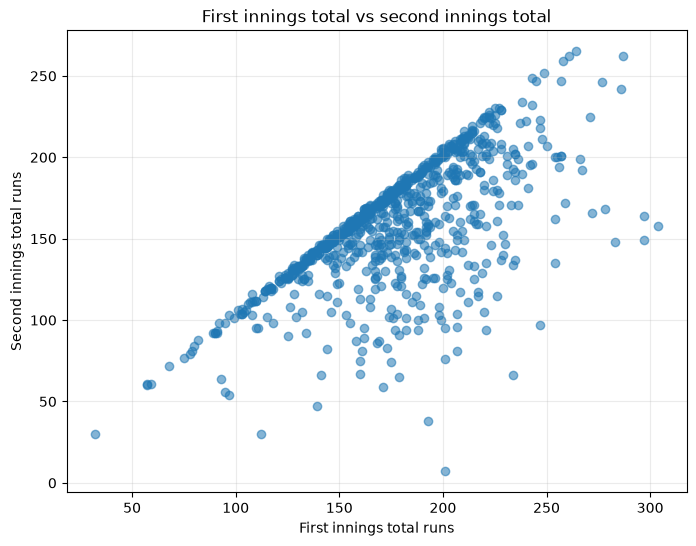

In [15]:
score_pivot = innings_summary.pivot_table(
    index="match_id", columns="innings", values="total_runs", aggfunc="sum"
)
score_pivot.columns = [f"innings_{int(c)}_total_runs" for c in score_pivot.columns]
paired_scores = score_pivot.dropna(subset=["innings_1_total_runs", "innings_2_total_runs"]).copy()

first_second_corr = paired_scores["innings_1_total_runs"].corr(paired_scores["innings_2_total_runs"])
print("Matches with both innings:", len(paired_scores))
print("Mean first innings total:", paired_scores["innings_1_total_runs"].mean())
print("Mean second innings total:", paired_scores["innings_2_total_runs"].mean())
print("Pearson correlation:", first_second_corr)

display(paired_scores.head())

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(paired_scores["innings_1_total_runs"], paired_scores["innings_2_total_runs"], alpha=0.55)
ax.set_title("First innings total vs second innings total")
ax.set_xlabel("First innings total runs")
ax.set_ylabel("Second innings total runs")
ax.grid(True, alpha=0.25)
plt.show()

## Step 15 — Join match results to competitions and innings totals

The match table contains toss, winner, home/away and result information. We attach competition name/format/season and innings totals to produce one match-level analysis table.

In [16]:
competition_match = matches.merge(
    competitions[["comp_id", "comp_name", "match_format", "season"]],
    on="comp_id", how="left", validate="many_to_one"
)
match_analysis = competition_match.merge(score_pivot.reset_index(), on="match_id", how="left", validate="one_to_one")

match_analysis["toss_winner_also_match_winner"] = np.where(
    match_analysis["toss_win_team_id"].notna() & match_analysis["win_team_id"].notna(),
    match_analysis["toss_win_team_id"] == match_analysis["win_team_id"], np.nan
)
match_analysis["home_team_won"] = np.where(
    match_analysis["win_team_id"].notna(),
    match_analysis["win_team_id"] == match_analysis["home_team_id"], np.nan
)

first_innings_teams = innings_summary.loc[
    innings_summary["innings"] == 1, ["match_id", "batting_team_id"]
].drop_duplicates("match_id").rename(columns={"batting_team_id": "first_innings_team_id"})
match_analysis = match_analysis.merge(first_innings_teams, on="match_id", how="left", validate="one_to_one")
valid_winner_first = match_analysis["win_team_id"].notna() & match_analysis["first_innings_team_id"].notna()
match_analysis["winner_batted_first"] = np.nan
match_analysis.loc[valid_winner_first, "winner_batted_first"] = (
    match_analysis.loc[valid_winner_first, "win_team_id"] == match_analysis.loc[valid_winner_first, "first_innings_team_id"]
).astype(int)

display(match_analysis[["match_id", "comp_name", "match_format", "season", "home_team", "away_team", "toss_opted", "win_team_id", "result", "innings_1_total_runs", "innings_2_total_runs"]].head(15))

,match_id,comp_name,match_format,season,home_team,away_team,toss_opted,win_team_id,result,innings_1_total_runs,innings_2_total_runs
0,13511,England in West Indies T20I Series 2022,T20I,2022,West Indies,England,Fielding,28.000,West Indies Won by 9 Wickets,103.000,104.000
1,13512,England in West Indies T20I Series 2022,T20I,2022,West Indies,England,Fielding,22.000,England Won by 1 Run,171.000,170.000
2,13513,England in West Indies T20I Series 2022,T20I,2022,West Indies,England,Fielding,28.000,West Indies Won by 20 runs,224.000,204.000
3,13514,England in West Indies T20I Series 2022,T20I,2022,West Indies,England,Fielding,22.000,England Won by 34 runs,193.000,159.000
4,13515,England in West Indies T20I Series 2022,T20I,2022,West Indies,England,Batting,28.000,West Indies Won by 17 runs,179.000,162.000
5,13522,West Indies in India T20I Series 2022,T20I,2022,India,West Indies,Fielding,18.000,India Won by 6 Wickets,157.000,162.000
6,13523,West Indies in India T20I Series 2022,T20I,2022,India,West Indies,Fielding,18.000,India Won by 8 Runs,186.000,178.000
7,13524,West Indies in India T20I Series 2022,T20I,2022,India,West Indies,Fielding,18.000,India Won by 17 runs,184.000,167.000
8,13612,Sri Lanka in Australia T20I Series 2022,T20I,2022,Australia,Sri Lanka,Fielding,20.000,Australia Won by 20 runs (D/L method),149.000,122.000
9,13613,Sri Lanka in Australia T20I Series 2022,T20I,2022,Australia,Sri Lanka,Fielding,20.000,Australia Won the one over Eliminator,164.000,164.000


## Step 16 — Toss decision and match outcome

The first table checks whether the team winning the toss also won the match. The second compares that share across toss choices. These are historical associations, not evidence that the toss caused a win.

In [17]:
known_results = match_analysis.dropna(subset=["win_team_id", "toss_win_team_id"]).copy()
known_results["toss_winner_won"] = known_results["toss_win_team_id"] == known_results["win_team_id"]

toss_summary = known_results.groupby("toss_opted", dropna=False).agg(
    matches=("match_id", "count"),
    toss_winner_also_won=("toss_winner_won", "sum"),
    share_toss_winner_also_won=("toss_winner_won", "mean"),
).reset_index()

toss_overall_rate = known_results["toss_winner_won"].mean()
print("Matches with toss winner and match winner:", len(known_results))
print("Toss winner also won:", int(known_results["toss_winner_won"].sum()))
print("Overall share:", toss_overall_rate)
display(toss_summary)

Matches with toss winner and match winner: 842
Toss winner also won: 430
Overall share: 0.5106888361045131


,toss_opted,matches,toss_winner_also_won,share_toss_winner_also_won
0,Batting,222,115,0.518
1,Fielding,620,315,0.508


## Step 17 — Team-level performance summary

We attach team names using the composite relationship `(comp_id, team_id)`. The output summarizes innings batted, average score, wickets lost, boundaries and innings won. Team IDs can be reused across competitions, so the competition-aware mapping is important.

In [18]:
team_innings = innings_summary.merge(
    matches[["match_id", "comp_id", "home_team_id", "away_team_id", "win_team_id", "toss_win_team_id"]],
    on="match_id", how="left", validate="many_to_one"
)
team_names = teams[["comp_id", "team_id", "team_name"]].drop_duplicates()
team_innings = team_innings.merge(
    team_names,
    left_on=["comp_id", "batting_team_id"],
    right_on=["comp_id", "team_id"],
    how="left", validate="many_to_one"
)
team_innings["team_won_match"] = team_innings["batting_team_id"] == team_innings["win_team_id"]
team_performance_summary = team_innings.groupby(
    ["batting_team_id", "team_name"], dropna=False
).agg(
    innings_batted=("match_id", "size"),
    average_total_runs=("total_runs", "mean"),
    median_total_runs=("total_runs", "median"),
    average_wickets_lost=("wickets", "mean"),
    total_fours=("fours", "sum"),
    total_sixes=("sixes", "sum"),
    innings_wins=("team_won_match", "sum"),
).reset_index().sort_values("average_total_runs", ascending=False)

display(team_performance_summary.head(20))

,batting_team_id,team_name,innings_batted,average_total_runs,median_total_runs,average_wickets_lost,total_fours,total_sixes,innings_wins
23,242,Sunrisers Hyderabad,72,183.236,179.500,6.347,1077,650,34
3,4,Punjab Kings,73,183.000,187.000,6.384,1126,689,35
4,5,Royal Challengers Bengaluru,76,181.237,181.500,5.829,1152,663,45
33,3508,Gujarat Titans,77,178.481,177.000,5.403,1239,518,47
1,2,Mumbai Indians,74,178.284,177.000,6.203,1116,655,30
2,3,Rajasthan Royals,77,177.909,185.000,5.896,1166,688,39
0,1,Chennai Super Kings,71,175.986,176.000,5.944,1007,569,31
34,3509,Lucknow Super Giants,73,174.699,176.000,6.192,1004,611,34
12,22,England,65,172.354,166.000,6.200,941,505,38
5,7,Delhi Capitals,71,171.197,172.000,6.380,1089,535,34


## Step 18 — Delivery-level numerical correlation

Pearson correlation ranges from -1 to +1. Positive values indicate that two variables tend to increase together; negative values indicate an inverse linear association; values close to zero indicate little linear association. Some pairs are mechanically related by definition, so interpret them cautiously.

In [19]:
numeric_columns = [
    "runs", "total_delivery_runs", "extras1_runs", "extras_2_runs", "bowl_speed",
    "innings", "overid", "over_ball_num", "innings_ball_num", "batting_order",
    "is_four", "is_six", "is_wicket"
]
numeric_columns = [c for c in numeric_columns if c in ball.columns]
ball_numeric = ball[numeric_columns].apply(pd.to_numeric, errors="coerce")
pearson_corr = ball_numeric.corr(method="pearson")
spearman_corr = ball_numeric.corr(method="spearman")

display(pearson_corr)

,runs,total_delivery_runs,extras1_runs,extras_2_runs,bowl_speed,innings,overid,over_ball_num,innings_ball_num,batting_order,is_four,is_six,is_wicket
runs,1.000,0.979,-0.150,-0.009,0.036,-0.007,0.051,-0.005,0.051,-0.038,0.556,0.703,-0.182
total_delivery_runs,0.979,1.000,0.054,0.019,0.036,-0.007,0.053,-0.004,0.054,-0.037,0.547,0.699,-0.193
extras1_runs,-0.150,0.054,1.000,0.029,-0.002,0.001,0.009,0.004,0.010,0.004,-0.070,-0.050,-0.046
extras_2_runs,-0.009,0.019,0.029,1.000,0.003,-0.001,0.005,-0.003,0.006,0.002,-0.004,-0.003,-0.003
bowl_speed,0.036,0.036,-0.002,0.003,1.000,-0.025,-0.045,0.018,-0.044,-0.039,0.034,0.019,0.014
innings,-0.007,-0.007,0.001,-0.001,-0.025,1.000,-0.057,-0.006,-0.056,0.016,0.003,-0.005,0.005
overid,0.051,0.053,0.009,0.005,-0.045,-0.057,1.000,0.007,0.997,0.666,-0.047,0.057,0.062
over_ball_num,-0.005,-0.004,0.004,-0.003,0.018,-0.006,0.007,1.000,0.059,0.058,-0.005,-0.004,0.003
innings_ball_num,0.051,0.054,0.010,0.006,-0.044,-0.056,0.997,0.059,1.000,0.666,-0.046,0.058,0.062
batting_order,-0.038,-0.037,0.004,0.002,-0.039,0.016,0.666,0.058,0.666,1.000,-0.063,-0.004,0.047


## Step 19 — Visualize the correlation matrix

The heatmap helps spot strong positive and negative associations across numeric delivery attributes. Correlation is not a causal effect and does not adjust for other variables such as batter, bowler, match format or over phase.

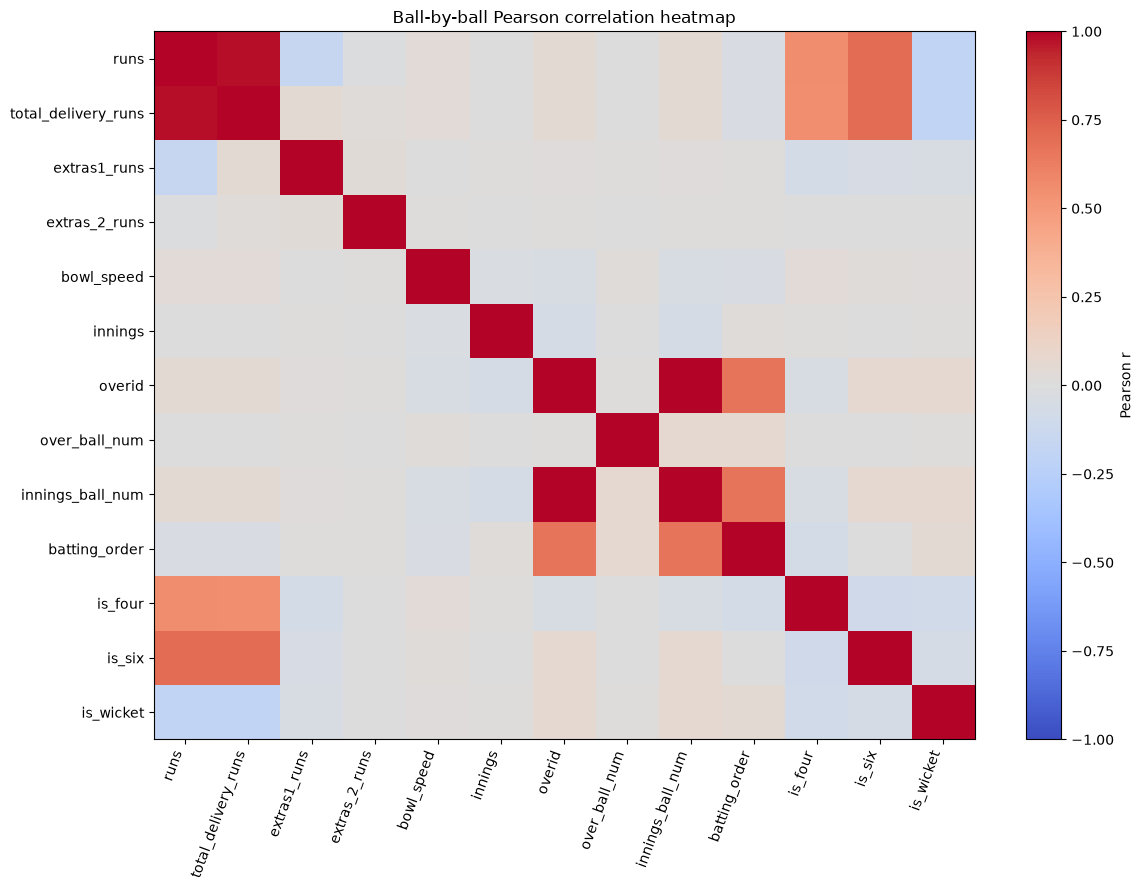

In [20]:
fig, ax = plt.subplots(figsize=(12, 9))
image = ax.imshow(pearson_corr, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
ax.set_xticks(range(len(pearson_corr.columns)))
ax.set_yticks(range(len(pearson_corr.index)))
ax.set_xticklabels(pearson_corr.columns, rotation=70, ha="right")
ax.set_yticklabels(pearson_corr.index)
ax.set_title("Ball-by-ball Pearson correlation heatmap")
fig.colorbar(image, ax=ax, label="Pearson r")
plt.tight_layout()
plt.show()

## Step 20 — Rank the strongest numeric relationships

We list each unique pair once and sort by absolute correlation. This helps identify the strongest associations, regardless of whether they are positive or negative.

In [21]:
pair_rows = []
for i, col_a in enumerate(numeric_columns):
    for col_b in numeric_columns[i + 1:]:
        r = pearson_corr.loc[col_a, col_b]
        pair_rows.append({
            "attribute_1": col_a,
            "attribute_2": col_b,
            "pearson_r": r,
            "absolute_r": abs(r) if pd.notna(r) else np.nan,
            "spearman_r": spearman_corr.loc[col_a, col_b],
        })
strongest_numeric_relationships = pd.DataFrame(pair_rows).sort_values("absolute_r", ascending=False)
display(strongest_numeric_relationships.head(25))

,attribute_1,attribute_2,pearson_r,absolute_r,spearman_r
58,overid,innings_ball_num,0.997,0.997,0.998
0,runs,total_delivery_runs,0.979,0.979,0.938
10,runs,is_six,0.703,0.703,0.449
21,total_delivery_runs,is_six,0.699,0.699,0.448
68,innings_ball_num,batting_order,0.666,0.666,0.670
59,overid,batting_order,0.666,0.666,0.669
9,runs,is_four,0.556,0.556,0.503
20,total_delivery_runs,is_four,0.547,0.547,0.499
22,total_delivery_runs,is_wicket,-0.193,0.193,-0.281
11,runs,is_wicket,-0.182,0.182,-0.258


## Step 21 — Compare deliveries by pace or spin bowling

For each bowling category we calculate number of deliveries, mean and median batter runs, total runs per delivery, four/six/wicket rates and mean positive bowling speed. Zero/negative speed values are excluded from the positive-speed average only; this is not a permanent correction of the source field.

,pace_or_spin,deliveries,mean_batter_runs,median_batter_runs,mean_total_delivery_runs,four_rate,six_rate,wicket_rate,mean_positive_speed,boundary_rate
0,Pace,123886,1.382,1.000,1.471,0.136,0.063,0.056,131.888,0.199
1,Spin,77113,1.276,1.000,1.323,0.084,0.064,0.051,91.975,0.148


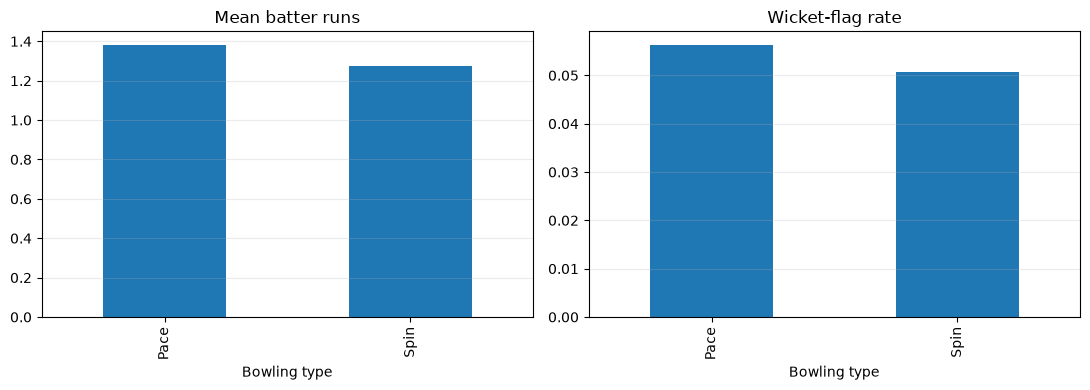

In [22]:
def grouped_ball_stats(df, group_col):
    grouped = df.groupby(group_col, dropna=False, observed=False).agg(
        deliveries=("runs", "size"),
        mean_batter_runs=("runs", "mean"),
        median_batter_runs=("runs", "median"),
        mean_total_delivery_runs=("total_delivery_runs", "mean"),
        four_rate=("is_four", "mean"),
        six_rate=("is_six", "mean"),
        wicket_rate=("is_wicket", "mean"),
        mean_positive_speed=("bowl_speed", lambda x: x[x > 0].mean() if (x > 0).any() else np.nan),
    ).reset_index()
    grouped["boundary_rate"] = grouped["four_rate"].fillna(0) + grouped["six_rate"].fillna(0)
    return grouped.sort_values("deliveries", ascending=False)

pace_spin_summary = grouped_ball_stats(ball, "pace_or_spin")
display(pace_spin_summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pace_spin_summary.plot(x="pace_or_spin", y="mean_batter_runs", kind="bar", ax=axes[0], legend=False, title="Mean batter runs")
pace_spin_summary.plot(x="pace_or_spin", y="wicket_rate", kind="bar", ax=axes[1], legend=False, title="Wicket-flag rate")
for ax in axes:
    ax.set_xlabel("Bowling type")
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## Step 22 — Compare batting hand and shot direction

This step compares left-handed/right-handed batters and on-side/off-side delivery classifications. Rates are proportions of delivery rows, not probabilities adjusted for different players or match situations.

In [23]:
batting_hand_summary = grouped_ball_stats(ball, "batting_type")
shot_direction_summary = grouped_ball_stats(ball, "on_or_off")
display(batting_hand_summary)
display(shot_direction_summary)

,batting_type,deliveries,mean_batter_runs,median_batter_runs,mean_total_delivery_runs,four_rate,six_rate,wicket_rate,mean_positive_speed,boundary_rate
1,RHB,131006,1.337,1.000,1.407,0.114,0.063,0.055,116.376,0.177
0,LHB,69993,1.348,1.000,1.427,0.119,0.064,0.053,116.914,0.184


,on_or_off,deliveries,mean_batter_runs,median_batter_runs,mean_total_delivery_runs,four_rate,six_rate,wicket_rate,mean_positive_speed,boundary_rate
0,Off-side,104875,1.125,1.000,1.180,0.130,0.031,0.055,117.690,0.161
1,On-side,96124,1.576,1.000,1.670,0.100,0.100,0.054,115.357,0.200


## Step 23 — Compare delivery style, bowling type, line/angle and stroke

The same descriptive summary is produced for each categorical delivery attribute. Review the `deliveries` column before interpreting small groups; very small categories can have unstable rates.

In [24]:
categorical_ball_columns = [
    "bowling_type", "stroke", "delivery_style", "over_or_around", "on_or_off", "batting_type", "pace_or_spin", "innings"
]
ball_group_summaries = {}
for col in categorical_ball_columns:
    if col in ball.columns:
        summary = grouped_ball_stats(ball, col)
        ball_group_summaries[col] = summary
        print(f"\\nSummary by {col}")
        display(summary.head(30))

\nSummary by bowling_type


,bowling_type,deliveries,mean_batter_runs,median_batter_runs,mean_total_delivery_runs,four_rate,six_rate,wicket_rate,mean_positive_speed,boundary_rate
6,Right-arm Leg-Break,28027,1.317,1.000,1.365,0.084,0.070,0.055,90.465,0.154
9,Right-arm medium-fast,27014,1.386,1.000,1.474,0.133,0.064,0.057,130.558,0.197
5,Right-arm Fast,26637,1.394,1.000,1.487,0.136,0.068,0.057,134.685,0.203
8,Right-arm medium,23919,1.385,1.000,1.475,0.135,0.062,0.055,130.611,0.197
11,Slow left-arm orthodox,23582,1.254,1.000,1.296,0.085,0.061,0.048,92.806,0.146
10,Right-arm offbreak,20948,1.248,1.000,1.297,0.083,0.060,0.046,93.829,0.142
7,Right-arm fast-medium,15380,1.387,1.000,1.468,0.134,0.066,0.061,132.073,0.200
4,Left-arm medium-fast,12492,1.391,1.000,1.483,0.144,0.061,0.053,129.883,0.204
2,Left-arm fast-medium,7780,1.336,1.000,1.422,0.132,0.059,0.054,131.287,0.191
3,Left-arm medium,6082,1.350,1.000,1.431,0.146,0.054,0.053,132.174,0.199


\nSummary by stroke


,stroke,deliveries,mean_batter_runs,median_batter_runs,mean_total_delivery_runs,four_rate,six_rate,wicket_rate,mean_positive_speed,boundary_rate
16,Pull shot,24645,1.955,1.000,2.024,0.156,0.138,0.081,120.682,0.294
1,Cover Drive,20779,1.592,1.000,1.607,0.220,0.037,0.048,116.941,0.257
29,Worked,20757,0.850,1.000,0.889,0.006,0.000,0.018,108.779,0.006
3,Flick,14836,1.535,1.000,1.669,0.127,0.065,0.060,122.801,0.192
11,Off Drive,14672,1.428,1.000,1.436,0.108,0.073,0.072,115.436,0.181
22,Square Cut,13776,1.223,1.000,1.261,0.175,0.010,0.038,113.477,0.185
12,On drive,11771,1.746,1.000,1.755,0.069,0.135,0.076,112.995,0.205
23,Square drive,11266,1.341,1.000,1.363,0.164,0.016,0.029,122.670,0.180
4,Frontfoot defensive,10721,0.291,0.000,0.304,0.012,0.000,0.036,115.143,0.012
17,Push,9610,0.510,0.000,0.518,0.016,0.000,0.022,115.025,0.016


\nSummary by delivery_style


,delivery_style,deliveries,mean_batter_runs,median_batter_runs,mean_total_delivery_runs,four_rate,six_rate,wicket_rate,mean_positive_speed,boundary_rate
25,Seamed In,22058,1.288,1.000,1.358,0.111,0.059,0.049,135.808,0.170
19,Orthodox,19239,1.256,1.000,1.292,0.083,0.061,0.048,91.720,0.145
15,Leg Break,15449,1.358,1.000,1.401,0.086,0.073,0.048,89.883,0.159
18,Off Cutter,15143,1.506,1.000,1.579,0.121,0.081,0.071,118.564,0.202
17,Off Break,14869,1.260,1.000,1.304,0.083,0.060,0.046,92.224,0.144
26,Seamed Out,14443,1.388,1.000,1.420,0.148,0.057,0.049,135.147,0.205
13,Inswing,12481,1.235,0.000,1.368,0.148,0.048,0.045,136.029,0.196
20,Out Swing,12176,1.254,0.000,1.287,0.172,0.041,0.049,135.203,0.214
12,Googly,11943,1.240,1.000,1.290,0.077,0.067,0.068,90.050,0.145
30,Straight,9753,1.704,1.000,1.762,0.154,0.088,0.056,133.617,0.243


... (6 outputs left out)

\nSummary by pace_or_spin


,pace_or_spin,deliveries,mean_batter_runs,median_batter_runs,mean_total_delivery_runs,four_rate,six_rate,wicket_rate,mean_positive_speed,boundary_rate
0,Pace,123886,1.382,1.000,1.471,0.136,0.063,0.056,131.888,0.199
1,Spin,77113,1.276,1.000,1.323,0.084,0.064,0.051,91.975,0.148


\nSummary by innings


,innings,deliveries,mean_batter_runs,median_batter_runs,mean_total_delivery_runs,four_rate,six_rate,wicket_rate,mean_positive_speed,boundary_rate
0,1,105727,1.353,1.000,1.426,0.115,0.065,0.053,116.932,0.180
1,2,95234,1.328,1.000,1.401,0.117,0.063,0.055,116.151,0.179
2,3,25,0.560,0.000,0.880,0.080,0.000,0.480,126.288,0.080
3,4,13,2.308,2.000,2.462,0.308,0.077,0.077,105.333,0.385


## Step 24 — Compare powerplay, middle and death overs

This phase grouping uses T20-style over boundaries: overs 1–6, 7–15 and 16 onward. It is descriptive and assumes the `overid` column uses conventional over numbering.

,phase,deliveries,mean_batter_runs,median_batter_runs,mean_total_delivery_runs,four_rate,six_rate,wicket_rate,mean_positive_speed,boundary_rate
1,Middle (7-15),92499,1.285,1.000,1.342,0.090,0.059,0.047,107.223,0.149
0,Powerplay (1-6),64046,1.307,1.000,1.388,0.155,0.054,0.045,126.378,0.210
2,Death (16+),44454,1.506,1.000,1.601,0.113,0.088,0.081,122.295,0.201


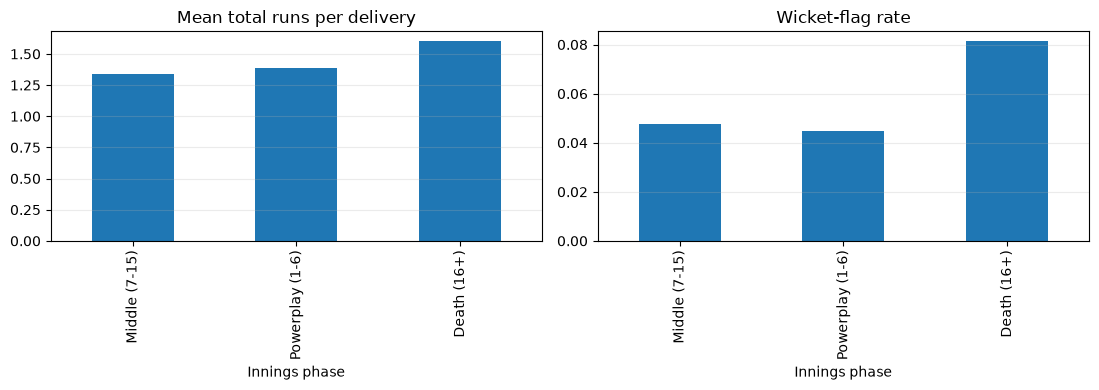

In [25]:
ball["phase"] = pd.cut(
    ball["overid"],
    bins=[0, 6, 15, 100],
    labels=["Powerplay (1-6)", "Middle (7-15)", "Death (16+)"]
)
phase_summary = grouped_ball_stats(ball, "phase")
display(phase_summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
phase_summary.plot(x="phase", y="mean_total_delivery_runs", kind="bar", ax=axes[0], legend=False, title="Mean total runs per delivery")
phase_summary.plot(x="phase", y="wicket_rate", kind="bar", ax=axes[1], legend=False, title="Wicket-flag rate")
for ax in axes:
    ax.set_xlabel("Innings phase")
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## Step 25 — Batter performance at match level

This groups the ball-by-ball data by match and striker. The balls-faced value is a practical proxy that excludes rows tagged as wides. Confirm the official scoring rules before using it as a scorecard-grade value.

In [26]:
player_match = ball.groupby(["match_id", "striker_id", "striker_name"], dropna=False).agg(
    recorded_delivery_rows=("runs", "size"),
    batter_runs=("runs", "sum"),
    fours=("is_four", "sum"),
    sixes=("is_six", "sum"),
).reset_index()

non_wide = (
    ball[ball["extras_type"].fillna("").str.lower() != "wide"]
    .groupby(["match_id", "striker_id"]).size()
    .rename("balls_faced").reset_index()
)
player_match = player_match.merge(non_wide, on=["match_id", "striker_id"], how="left", validate="one_to_one")
player_match["strike_rate"] = np.where(
    player_match["balls_faced"] > 0,
    100 * player_match["batter_runs"] / player_match["balls_faced"],
    np.nan
)

dismissals = (
    ball[ball["dismissed_player_id"].notna()]
    .groupby(["match_id", "dismissed_player_id"]).size()
    .rename("dismissals_suffered").reset_index()
)
dismissals["dismissed_player_id"] = dismissals["dismissed_player_id"].astype(int)
player_match = player_match.merge(
    dismissals,
    left_on=["match_id", "striker_id"],
    right_on=["match_id", "dismissed_player_id"],
    how="left"
)
player_match["dismissals_suffered"] = player_match["dismissals_suffered"].fillna(0).astype(int)
player_match = player_match.drop(columns=["dismissed_player_id"], errors="ignore")

display(player_match.head(20))

,match_id,striker_id,striker_name,recorded_delivery_rows,batter_runs,fours,sixes,balls_faced,strike_rate,dismissals_suffered
0,13511,478,Eoin Morgan,32,17,0,1,29.000,58.621,1
1,13511,479,Adil Rashid,18,22,3,0,18.000,122.222,1
2,13511,722,Liam Dawson,9,2,0,0,9.000,22.222,1
3,13511,786,Chris Jordan,23,28,0,3,23.000,121.739,1
4,13511,1187,Jason Roy,6,6,0,1,6.000,100.000,1
5,13511,1210,James Vince,12,14,2,1,12.000,116.667,1
6,13511,1596,Moeen Ali,1,0,0,0,1.000,0.000,1
7,13511,1924,Sam Billings,4,2,0,0,4.000,50.000,1
8,13511,3125,Nicholas Pooran,29,27,2,0,29.000,93.103,0
9,13511,3639,Brandon King,49,52,4,1,49.000,106.122,0


## Step 26 — Attach batting order and study batting position

Because the playing-eleven table contains repeated player keys with different batting orders, we aggregate available batting orders using the median for each `(match_id, player_id)` before joining. Treat batting order as an approximate lineup attribute and inspect repeated keys separately.

In [27]:
played_rows = pe[pe["is_played"].astype(str).str.lower().eq("true")].copy()
played_orders = played_rows.groupby(["match_id", "player_id"], as_index=False).agg(
    batting_order_median=("batting_order", "median")
)
player_match = player_match.merge(
    played_orders,
    left_on=["match_id", "striker_id"],
    right_on=["match_id", "player_id"],
    how="left",
    validate="many_to_one"
).drop(columns=["player_id"], errors="ignore")

order_rows = player_match.dropna(subset=["batting_order_median"]).copy()
order_corr_rows = []
for metric in ["balls_faced", "batter_runs", "strike_rate", "fours", "sixes"]:
    order_corr_rows.append({
        "attribute_1": "batting_order_median",
        "attribute_2": metric,
        "pearson_r": order_rows["batting_order_median"].corr(order_rows[metric]),
        "sample_player_innings": len(order_rows),
    })
batting_order_relationships = pd.DataFrame(order_corr_rows)
display(batting_order_relationships)

order_bins = [0, 3, 6, 9, 13]
order_labels = ["1-3", "4-6", "7-9", "10-13"]
order_rows["batting_order_group"] = pd.cut(
    order_rows["batting_order_median"], bins=order_bins, labels=order_labels
)
batting_order_group_summary = order_rows.groupby("batting_order_group", observed=True).agg(
    player_innings=("striker_id", "size"),
    average_balls_faced=("balls_faced", "mean"),
    average_runs=("batter_runs", "mean"),
    average_strike_rate=("strike_rate", "mean"),
    average_fours=("fours", "mean"),
    average_sixes=("sixes", "mean"),
).reset_index()
display(batting_order_group_summary)

,attribute_1,attribute_2,pearson_r,sample_player_innings
0,batting_order_median,balls_faced,-0.395,13717
1,batting_order_median,batter_runs,-0.357,13717
2,batting_order_median,strike_rate,-0.105,13717
3,batting_order_median,fours,-0.383,13717
4,batting_order_median,sixes,-0.224,13717


,batting_order_group,player_innings,average_balls_faced,average_runs,average_strike_rate,average_fours,average_sixes
0,1-3,5112,18.766,26.943,121.552,2.635,1.235
1,4-6,4677,14.879,20.655,122.229,1.544,1.015
2,7-9,3020,7.970,10.518,114.364,0.775,0.539
3,10-13,908,3.919,3.546,83.553,0.258,0.128


## Step 27 — Overall batter and bowler summaries

The batter summary aggregates match-level batter records by player ID and name. The bowler summary aggregates deliveries and wicket flags by bowler. A delivery wicket flag can include dismissals not credited to the bowler (for example, run outs), so interpret `wicket_events` accordingly.

In [28]:
batter_overall_summary = player_match.groupby(["striker_id", "striker_name"], dropna=False).agg(
    matches_with_batting=("match_id", "nunique"),
    recorded_delivery_rows=("recorded_delivery_rows", "sum"),
    balls_faced=("balls_faced", "sum"),
    batter_runs=("batter_runs", "sum"),
    fours=("fours", "sum"),
    sixes=("sixes", "sum"),
    dismissals_suffered=("dismissals_suffered", "sum"),
    average_runs_per_innings=("batter_runs", "mean"),
    average_strike_rate=("strike_rate", "mean"),
).reset_index()
batter_overall_summary["overall_strike_rate"] = np.where(
    batter_overall_summary["balls_faced"] > 0,
    100 * batter_overall_summary["batter_runs"] / batter_overall_summary["balls_faced"],
    np.nan
)
batter_overall_summary = batter_overall_summary.sort_values("batter_runs", ascending=False)

display(batter_overall_summary.head(20))

bowler_overall_summary = ball.groupby(["bowler_id", "bowler_name"], dropna=False).agg(
    deliveries_recorded=("runs", "size"),
    batter_runs_on_bowler_deliveries=("runs", "sum"),
    total_runs_on_bowler_deliveries=("total_delivery_runs", "sum"),
    wicket_events=("is_wicket", "sum"),
    fours_hit=("is_four", "sum"),
    sixes_hit=("is_six", "sum"),
    positive_speed_mean=("bowl_speed", lambda x: x[x > 0].mean() if (x > 0).any() else np.nan),
).reset_index()
bowler_overall_summary["wicket_events_per_100_deliveries"] = (
    100 * bowler_overall_summary["wicket_events"] / bowler_overall_summary["deliveries_recorded"]
)
bowler_overall_summary = bowler_overall_summary.sort_values("wicket_events", ascending=False)
display(bowler_overall_summary.head(20))

,striker_id,striker_name,matches_with_batting,recorded_delivery_rows,balls_faced,batter_runs,fours,sixes,dismissals_suffered,average_runs_per_innings,average_strike_rate,overall_strike_rate
96,1699,Suryakumar Yadav,139,2850,"2,761.000",4595,432,248,119,33.058,146.255,166.425
52,813,Jos Buttler,121,2920,"2,829.000",4396,431,204,107,36.331,134.685,155.391
401,6281,Abhishek Sharma,134,2436,"2,317.000",4332,420,283,130,32.328,154.754,186.966
405,6288,Shubman Gill,112,2804,"2,711.000",4050,407,142,100,36.161,129.074,149.391
541,7897,Namboori Tilak Varma,127,2631,"2,515.000",3596,275,172,90,28.315,128.529,142.982
3,47,Virat Kohli,92,2545,"2,456.000",3567,344,124,76,38.772,125.612,145.236
268,4117,Ishan Kishan,122,2506,"2,411.000",3529,368,157,116,28.926,123.003,146.371
115,2258,Sanju Samson,124,2305,"2,232.000",3451,320,187,110,27.831,128.465,154.615
185,3125,Nicholas Pooran,115,2092,"1,973.000",3098,210,222,96,26.939,136.936,157.020
469,6819,Yashasvi Jaiswal,89,1936,"1,872.000",2927,350,129,83,32.888,140.162,156.357


,bowler_id,bowler_name,deliveries_recorded,batter_runs_on_bowler_deliveries,total_runs_on_bowler_deliveries,wicket_events,fours_hit,sixes_hit,positive_speed_mean,wicket_events_per_100_deliveries
305,6464,Arshdeep Singh,3432,4638,4976,211,533,173,131.843,6.148
210,4722,Rashid Khan,2780,3357,3466,159,185,170,93.457,5.719
284,6256,Varun Chakravarthy,2182,2774,2888,138,189,156,96.932,6.324
240,4900,Wanindu Hasaranga,2054,2668,2735,135,157,144,84.984,6.573
50,1612,Yuzvendra Chahal,2218,2985,3093,131,174,161,87.359,5.906
370,7503,Ravi Bishnoi,2429,3121,3282,130,247,149,97.220,5.352
99,2876,Axar Patel,2707,3461,3556,129,238,181,94.057,4.765
14,360,Bhuvneshwar Kumar,2314,2959,3133,122,314,113,130.850,5.272
149,3644,Kuldeep Yadav,1965,2505,2578,119,129,145,87.044,6.056
87,2633,Jason Holder,2032,2782,2939,118,251,122,125.593,5.807


## Step 28 — Data-quality checks for playing-eleven records

This examines repeated `(match_id, team_id, player_id)` combinations, rows marked not played, missing batting orders among played rows and the two impact-player flags.

In [29]:
pe_repeated = pe[pe.duplicated(["match_id", "team_id", "player_id"], keep=False)].sort_values(
    ["match_id", "team_id", "player_id", "batting_order"]
)
not_played = pe[~pe["is_played"]]
played_missing_order = pe[pe["is_played"] & pe["batting_order"].isna()]
impact_both = ((pe["is_impact"] == 1) & (pe["is_impact_off"] == 1)).sum()

playing_eleven_quality = pd.DataFrame([
    {"check": "rows in repeated (match, team, player) key groups", "value": len(pe_repeated)},
    {"check": "number of repeated player key groups", "value": pe.duplicated(["match_id", "team_id", "player_id"]).sum()},
    {"check": "rows marked is_played=False", "value": len(not_played)},
    {"check": "played rows with missing batting_order", "value": len(played_missing_order)},
    {"check": "rows with both impact flags equal to 1", "value": int(impact_both)},
    {"check": "is_impact=1 rows", "value": int((pe["is_impact"] == 1).sum())},
    {"check": "is_impact_off=1 rows", "value": int((pe["is_impact_off"] == 1).sum())},
])
display(playing_eleven_quality)
display(pe_repeated.head(30))

,check,value
0,"rows in repeated (match, team, player) key groups",75
1,number of repeated player key groups,40
2,rows marked is_played=False,8667
3,played rows with missing batting_order,11
4,rows with both impact flags equal to 1,0
5,is_impact=1 rows,558
6,is_impact_off=1 rows,558


,match_id,team_id,player_id,batting_order,is_played,is_captain,is_wk,is_impact,is_impact_off
206,13613,20,223,5.000,True,False,False,0,0
208,13613,20,223,6.000,True,False,False,0,0
200,13613,20,250,2.000,True,True,False,0,0
205,13613,20,250,4.000,True,True,False,0,0
199,13613,20,838,1.000,True,False,False,0,0
204,13613,20,838,4.000,True,False,False,0,0
201,13613,20,2639,2.000,True,False,False,0,0
209,13613,20,2639,6.000,True,False,False,0,0
198,13613,20,3539,1.000,True,False,False,0,0
203,13613,20,3539,3.000,True,False,False,0,0


## Step 29 — Bowling-speed and delivery-flag anomalies

Zero speeds may represent unrecorded values, but the source data dictionary should confirm this before converting them to missing values. Values above 200 and negative values are flagged for investigation. The four/six checks compare run values with boundary flags.

In [30]:
speed_quality = pd.DataFrame([
    {"check": "zero bowling speeds", "value": int((ball["bowl_speed"] == 0).sum())},
    {"check": "negative bowling speeds", "value": int((ball["bowl_speed"] < 0).sum())},
    {"check": "bowling speeds above 200", "value": int((ball["bowl_speed"] > 200).sum())},
    {"check": "maximum bowling speed", "value": ball["bowl_speed"].max()},
    {"check": "runs=4 but is_four=False", "value": int(((ball["runs"] == 4) & (~ball["is_four"])).sum())},
    {"check": "runs=6 but is_six=False", "value": int(((ball["runs"] == 6) & (~ball["is_six"])).sum())},
    {"check": "wicket rows with missing dismissal type", "value": int((ball["is_wicket"] & ball["dismissal_type"].isna()).sum())},
])
display(speed_quality)

extreme_speed_rows = ball[(ball["bowl_speed"] < 0) | (ball["bowl_speed"] > 200)]
display(extreme_speed_rows[["match_id", "innings", "overid", "bowler_name", "bowl_speed", "delivery_ist_time"]].head(30))

,check,value
0,zero bowling speeds,"77,861.000"
1,negative bowling speeds,1.000
2,bowling speeds above 200,19.000
3,maximum bowling speed,"1,456.100"
4,runs=4 but is_four=False,20.000
5,runs=6 but is_six=False,3.000
6,wicket rows with missing dismissal type,0.000


,match_id,innings,overid,bowler_name,bowl_speed,delivery_ist_time
1761,13524,1,4,Romario Shepherd,"1,135.600",2022-02-20 19:16:44 UTC
6756,14108,2,9,Axar Patel,-1.000,2022-04-07 22:15:54 UTC
8782,14116,2,19,Kagiso Rabada,"1,339.600",2022-04-13 23:16:45 UTC
10252,14122,2,19,Dwayne Bravo,"1,305.000",2022-04-17 23:03:51 UTC
14909,14143,1,11,Ravindra Jadeja,967.000,2022-05-04 20:16:47 UTC
15236,14144,2,4,Khaleel Ahmed,"1,456.100",2022-05-05 21:50:29 UTC
19019,14160,1,16,Varun Chakravarthy,931.000,2022-05-18 20:48:17 UTC
24099,15795,1,1,Bhuvneshwar Kumar,201.000,2022-06-26 23:20:09 UTC
26821,16259,2,2,Jacob Duffy,"1,351.000",2022-07-20 22:29:17 UTC
27789,16317,2,7,Keshav Maharaj,914.000,2022-07-31 21:35:18 UTC


## Step 30 — Add player names to ball records using relational keys (example)

This is a practical demonstration of joining the player mapping to ball-by-ball rows. We first attach `comp_id` through the match table, then map the striker using `(comp_id, batting_team_id, striker_id)`. We map the bowler using `(comp_id, bowling_team_id, bowler_id)`. This avoids joining only on player ID.

In [31]:
ball_comp_for_names = ball[[
    "match_id", "batting_team_id", "bowling_team_id", "striker_id", "striker_name", "bowler_id", "bowler_name"
]].merge(
    matches[["match_id", "comp_id"]], on="match_id", how="left", validate="many_to_one"
)

striker_lookup = mapping[["comp_id", "team_id", "player_id", "player_name"]].rename(columns={
    "team_id": "batting_team_id", "player_id": "striker_id", "player_name": "mapped_striker_name"
})
bowler_lookup = mapping[["comp_id", "team_id", "player_id", "player_name"]].rename(columns={
    "team_id": "bowling_team_id", "player_id": "bowler_id", "player_name": "mapped_bowler_name"
})

ball_player_names = ball_comp_for_names.merge(
    striker_lookup, on=["comp_id", "batting_team_id", "striker_id"], how="left", validate="many_to_one"
).merge(
    bowler_lookup, on=["comp_id", "bowling_team_id", "bowler_id"], how="left", validate="many_to_one"
)

display(ball_player_names[["match_id", "comp_id", "striker_id", "striker_name", "mapped_striker_name", "bowler_id", "bowler_name", "mapped_bowler_name"]].head(15))

,match_id,comp_id,striker_id,striker_name,mapped_striker_name,bowler_id,bowler_name,mapped_bowler_name
0,13511,1331,1187,Jason Roy,Jason Roy,1772,Sheldon Cottrell,Sheldon Cottrell
1,13511,1331,1187,Jason Roy,Jason Roy,1772,Sheldon Cottrell,Sheldon Cottrell
2,13511,1331,1187,Jason Roy,Jason Roy,1772,Sheldon Cottrell,Sheldon Cottrell
3,13511,1331,1187,Jason Roy,Jason Roy,1772,Sheldon Cottrell,Sheldon Cottrell
4,13511,1331,1187,Jason Roy,Jason Roy,1772,Sheldon Cottrell,Sheldon Cottrell
5,13511,1331,1187,Jason Roy,Jason Roy,1772,Sheldon Cottrell,Sheldon Cottrell
6,13511,1331,6273,Tom Banton,Tom Banton,2633,Jason Holder,Jason Holder
7,13511,1331,6273,Tom Banton,Tom Banton,2633,Jason Holder,Jason Holder
8,13511,1331,6273,Tom Banton,Tom Banton,2633,Jason Holder,Jason Holder
9,13511,1331,6273,Tom Banton,Tom Banton,2633,Jason Holder,Jason Holder


## Step 31 — Competition-level summaries

This groups match outcomes by competition, format and season. Counts of decisive matches use non-missing match winners. `home_team_won` and `toss_winner_also_match_winner` are only interpreted where the relevant result fields are present.

In [32]:
match_analysis["home_team_won_numeric"] = match_analysis["home_team_won"].astype("float")
match_analysis["toss_winner_won_numeric"] = match_analysis["toss_winner_also_match_winner"].astype("float")
competition_match_summary = match_analysis.groupby(
    ["comp_id", "comp_name", "match_format", "season"], dropna=False
).agg(
    matches=("match_id", "nunique"),
    decisive_matches=("win_team_id", "count"),
    home_wins=("home_team_won_numeric", "sum"),
    toss_winner_match_wins=("toss_winner_won_numeric", "sum"),
).reset_index()
display(competition_match_summary.head(25))

,comp_id,comp_name,match_format,season,matches,decisive_matches,home_wins,toss_winner_match_wins
0,1331,England in West Indies T20I Series 2022,T20I,2022,5,5,3.000,2.000
1,1335,West Indies in India T20I Series 2022,T20I,2022,3,3,3.000,1.000
2,1345,Sri Lanka in Australia T20I Series 2022,T20I,2022,5,5,4.000,2.000
3,1358,IPL 2022,T20,2022,74,74,34.000,37.000
4,1435,Australia in Sri Lanka T20I Series 2022,T20I,2022,3,3,1.000,2.000
5,1439,South Africa in India T20I Series 2022,T20I,2022,5,4,2.000,2.000
6,1452,Bangladesh in West Indies T20I Series 2022,T20I,2022,3,2,2.000,1.000
7,1458,Afghanistan in Zimbabwe T20I Series 2022,T20I,2022,3,3,0.000,2.000
8,1474,India in Ireland T20I Series 2022,T20I,2022,2,2,0.000,2.000
9,1494,India in England T20I Series 2022,T20I,2022,3,3,1.000,2.000


## Step 32 — Summarize the most important relationships

This cell prints a compact list of useful associations calculated above. It reiterates that these are sample-level descriptive relationships, not causal explanations.

In [33]:
print("DELIVERY-LEVEL NUMERIC RELATIONSHIPS")
for a, b in [("runs", "is_four"), ("runs", "is_six"), ("runs", "is_wicket"), ("overid", "innings_ball_num")]:
    if a in pearson_corr.index and b in pearson_corr.columns:
        print(f"{a} vs {b}: Pearson r = {pearson_corr.loc[a, b]:.3f}")

print("\\nPACE / SPIN COMPARISON")
display(pace_spin_summary[["pace_or_spin", "deliveries", "mean_batter_runs", "four_rate", "six_rate", "wicket_rate", "mean_positive_speed"]])

print("\\nINNINGS SCORE RELATIONSHIP")
print(f"Paired matches: {len(paired_scores)}; correlation: {first_second_corr:.3f}")

print("\\nBATTING ORDER RELATIONSHIPS")
display(batting_order_relationships)

DELIVERY-LEVEL NUMERIC RELATIONSHIPS
runs vs is_four: Pearson r = 0.556
runs vs is_six: Pearson r = 0.703
runs vs is_wicket: Pearson r = -0.182
overid vs innings_ball_num: Pearson r = 0.997
\nPACE / SPIN COMPARISON


,pace_or_spin,deliveries,mean_batter_runs,four_rate,six_rate,wicket_rate,mean_positive_speed
0,Pace,123886,1.382,0.136,0.063,0.056,131.888
1,Spin,77113,1.276,0.084,0.064,0.051,91.975


\nINNINGS SCORE RELATIONSHIP
Paired matches: 845; correlation: 0.656
\nBATTING ORDER RELATIONSHIPS


,attribute_1,attribute_2,pearson_r,sample_player_innings
0,batting_order_median,balls_faced,-0.395,13717
1,batting_order_median,batter_runs,-0.357,13717
2,batting_order_median,strike_rate,-0.105,13717
3,batting_order_median,fours,-0.383,13717
4,batting_order_median,sixes,-0.224,13717


## Step 33 — Export all analysis tables to CSV

All original files remain unchanged. Derived tables are saved into `cricket_analysis_outputs/` so they can be reused in Excel, Power BI, or another Python workflow.

In [34]:
# Build reusable export dictionary.
exports = {
    "dataset_overview.csv": dataset_overview,
    "all_column_profiles.csv": all_column_profiles,
    "missing_value_summary.csv": missing_summary,
    "duplicate_summary.csv": duplicate_summary,
    "candidate_key_checks.csv": candidate_key_checks,
    "foreign_key_relationship_checks.csv": foreign_key_checks,
    "ball_player_role_mapping_checks.csv": ball_player_role_mapping_checks,
    "dataset_coverage.csv": coverage,
    "innings_summary.csv": innings_summary,
    "first_vs_second_innings_scores.csv": paired_scores.reset_index(),
    "joined_match_analysis.csv": match_analysis,
    "toss_choice_vs_match_win.csv": toss_summary,
    "team_performance_summary.csv": team_performance_summary,
    "ball_numeric_correlation_matrix.csv": pearson_corr.reset_index().rename(columns={"index": "attribute"}),
    "strongest_numeric_relationships.csv": strongest_numeric_relationships,
    "pace_spin_summary.csv": pace_spin_summary,
    "batting_hand_summary.csv": batting_hand_summary,
    "shot_direction_summary.csv": shot_direction_summary,
    "phase_summary.csv": phase_summary,
    "batter_match_summary.csv": player_match,
    "batter_overall_summary.csv": batter_overall_summary,
    "batting_order_relationships.csv": batting_order_relationships,
    "batting_order_group_summary.csv": batting_order_group_summary,
    "bowler_overall_summary.csv": bowler_overall_summary,
    "playing_eleven_quality_checks.csv": playing_eleven_quality,
    "bowling_speed_and_flag_quality.csv": speed_quality,
    "competition_match_summary.csv": competition_match_summary,
}

for filename, table in exports.items():
    table.to_csv(OUTPUT_DIR / filename, index=False)

for column_name, table in ball_group_summaries.items():
    safe_name = column_name.replace("/", "_")
    table.to_csv(OUTPUT_DIR / f"ball_group_{safe_name}.csv", index=False)

ball_player_names.head(5000).to_csv(OUTPUT_DIR / "ball_player_name_join_sample_5000.csv", index=False)
print(f"Saved {len(exports) + len(ball_group_summaries) + 1} output CSV files to:")
print(OUTPUT_DIR)

Saved 36 output CSV files to:
C:\Users\LENOVO\OneDrive\Desktop\RR\Data Pack\cricket_analysis_outputs


## Step 34 — Save visualizations

The main figures are exported as PNG files so they can be inserted into a project report or presentation.

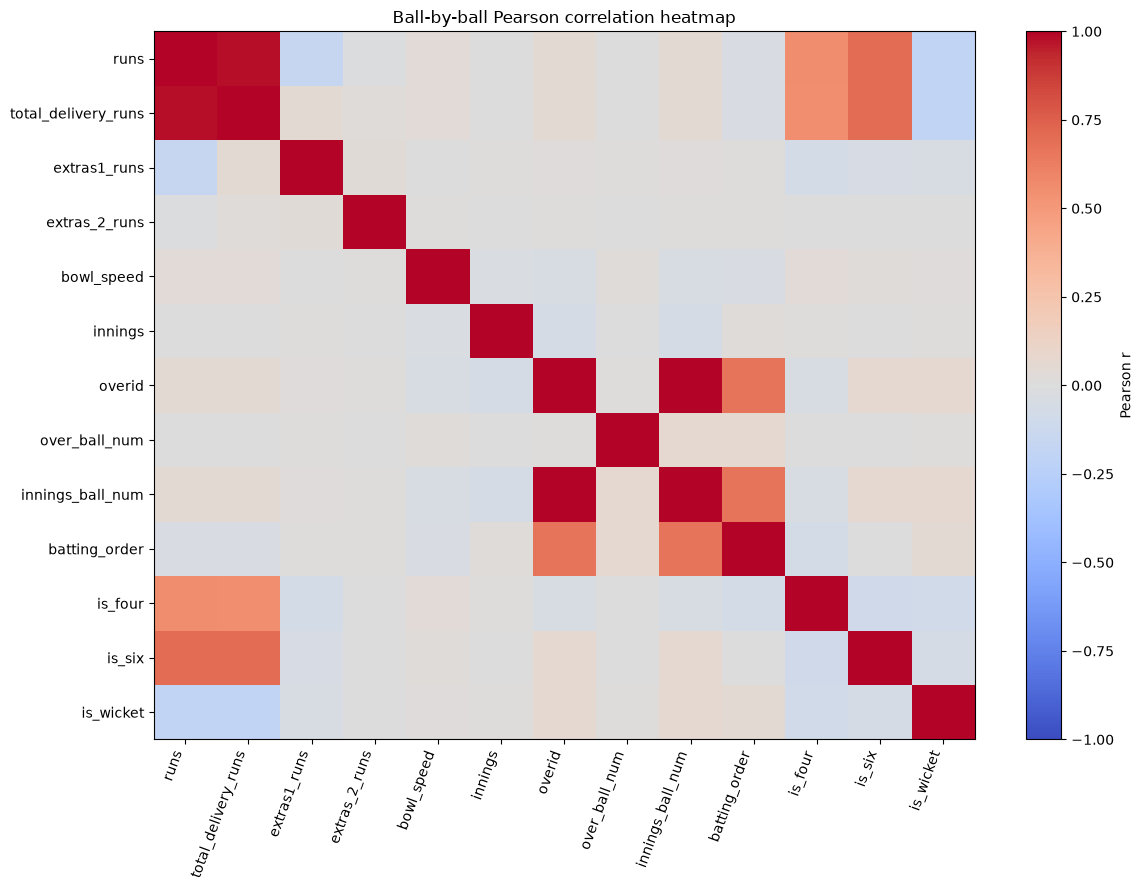

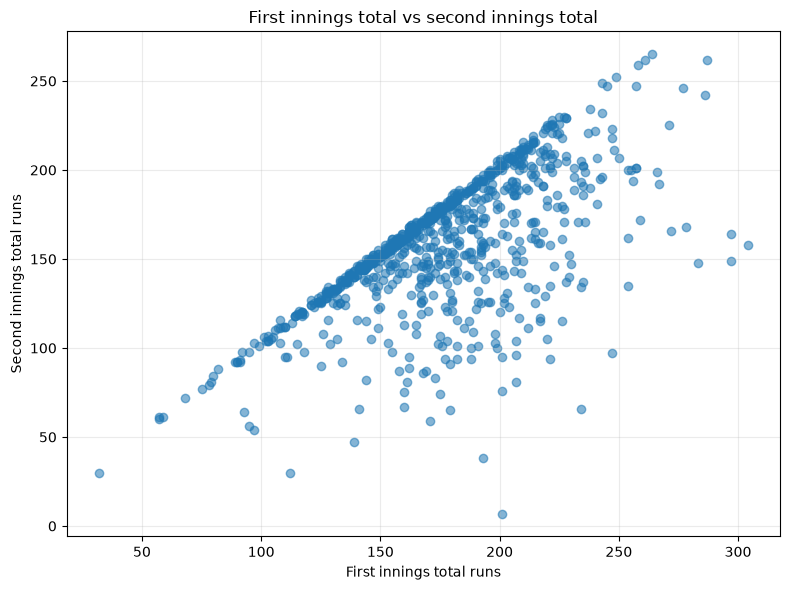

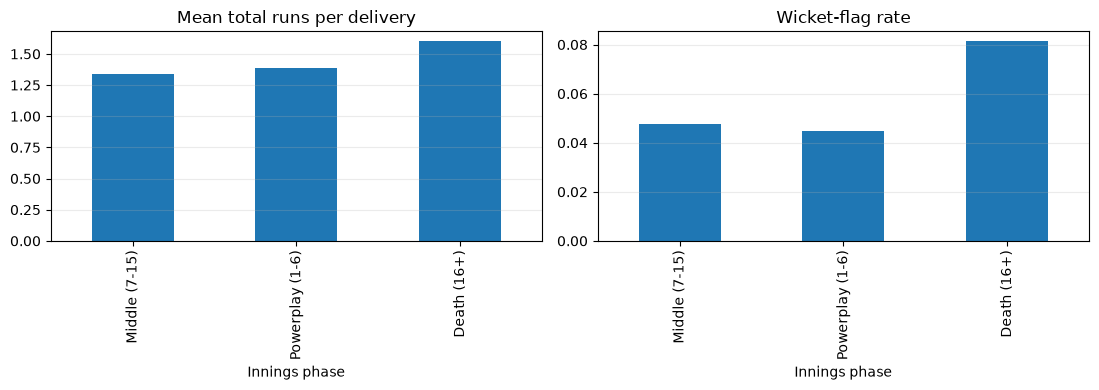

Charts saved in: C:\Users\LENOVO\OneDrive\Desktop\RR\Data Pack\cricket_analysis_outputs


In [35]:
# Correlation heatmap
fig, ax = plt.subplots(figsize=(12, 9))
image = ax.imshow(pearson_corr, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
ax.set_xticks(range(len(pearson_corr.columns)))
ax.set_yticks(range(len(pearson_corr.index)))
ax.set_xticklabels(pearson_corr.columns, rotation=70, ha="right")
ax.set_yticklabels(pearson_corr.index)
ax.set_title("Ball-by-ball Pearson correlation heatmap")
fig.colorbar(image, ax=ax, label="Pearson r")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "01_ball_correlation_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# First vs second innings scatter
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(paired_scores["innings_1_total_runs"], paired_scores["innings_2_total_runs"], alpha=0.55)
ax.set_title("First innings total vs second innings total")
ax.set_xlabel("First innings total runs")
ax.set_ylabel("Second innings total runs")
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_first_vs_second_innings.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Phase scoring/wicket rate
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
phase_summary.plot(x="phase", y="mean_total_delivery_runs", kind="bar", ax=axes[0], legend=False, title="Mean total runs per delivery")
phase_summary.plot(x="phase", y="wicket_rate", kind="bar", ax=axes[1], legend=False, title="Wicket-flag rate")
for ax in axes:
    ax.set_xlabel("Innings phase")
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_phase_scoring_and_wickets.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Charts saved in:", OUTPUT_DIR)

## Step 35 — Final interpretation and recommendations

### Main relationships to discuss in a report

1. **Runs and boundary indicators:** runs are positively associated with `is_four` and `is_six`. These are partly definitional relationships, so they are not independent discoveries.
2. **Wickets and runs:** the delivery-level relationship is descriptive and can be affected by dismissal types, extras, and match context.
3. **Pace vs spin:** compare average runs, boundary rates, wicket rates and speed values, but do not conclude that bowling type alone causes the difference.
4. **Innings phase:** compare powerplay, middle and death overs. The phase definition assumes T20-style over ranges.
5. **Batting order:** later positions tend to have fewer batting opportunities. Use player-match records rather than treating every delivery as an independent player observation.
6. **First vs second innings:** analyze only matches with both innings totals present. Match conditions and target context affect this relationship.
7. **Toss and result:** toss-winner success is a historical proportion, not proof that winning the toss determines the match.

### Data preparation warnings

- Investigate repeated playing-eleven keys before using batting order as a definitive label.
- Verify that zero bowling speed means unrecorded speed before converting it to missing.
- Inspect negative and extreme speeds before building a model.
- Do not interpret missing delivery data for abandoned matches as zero runs.
- Verify how `runs`, `extras1_runs` and `extras_2_runs` are defined in the original data dictionary.
- Avoid target leakage: do not use fields such as final winner, result, or player of the match when predicting a match outcome before the match is played.

### Next-stage modelling ideas

- Match-level winner prediction using pre-match information only.
- Delivery-level run or wicket probability prediction.
- Batter and bowler performance comparisons adjusted for match and opponent context.

For machine-learning evaluation, split training and test data by match or by date where appropriate. Do not randomly split individual delivery rows from the same match across train and test if the goal is to predict unseen matches.

## Step 36 — Final confirmation

The following cell reports the output folder and counts the generated files. Your source CSV files have not been overwritten.

In [36]:
output_files = sorted(p.name for p in OUTPUT_DIR.iterdir() if p.is_file())
print("Analysis completed.")
print("Output folder:", OUTPUT_DIR.resolve())
print("Number of generated output files:", len(output_files))
for filename in output_files:
    print(" -", filename)

Analysis completed.
Output folder: C:\Users\LENOVO\OneDrive\Desktop\RR\Data Pack\cricket_analysis_outputs
Number of generated output files: 39
 - 01_ball_correlation_heatmap.png
 - 02_first_vs_second_innings.png
 - 03_phase_scoring_and_wickets.png
 - all_column_profiles.csv
 - ball_group_batting_type.csv
 - ball_group_bowling_type.csv
 - ball_group_delivery_style.csv
 - ball_group_innings.csv
 - ball_group_on_or_off.csv
 - ball_group_over_or_around.csv
 - ball_group_pace_or_spin.csv
 - ball_group_stroke.csv
 - ball_numeric_correlation_matrix.csv
 - ball_player_name_join_sample_5000.csv
 - ball_player_role_mapping_checks.csv
 - batter_match_summary.csv
 - batter_overall_summary.csv
 - batting_hand_summary.csv
 - batting_order_group_summary.csv
 - batting_order_relationships.csv
 - bowler_overall_summary.csv
 - bowling_speed_and_flag_quality.csv
 - candidate_key_checks.csv
 - competition_match_summary.csv
 - dataset_coverage.csv
 - dataset_overview.csv
 - duplicate_summary.csv
 - first_v

---
# PART B: Identify the Most Reliable Players Under Pressure

## B0. What the problem statement asks for

| Requirement in the problem statement | Where this notebook answers it |
|---|---|
| **Define pressure yourself** and explain why it is meaningful | Steps 39 to 41 |
| **Show how the definition separates pressure from ordinary situations** | Step 41 (swing in win probability, required rate, wickets, balls left) |
| Measure batters **and** bowlers **against their usual performance** | Steps 42 to 44 |
| **Fair comparisons**: sample sizes, eligibility, match contexts, IPL vs T20I | Steps 43 to 45 and 49 |
| **Evidence for the top 10** (tables and charts) | Steps 45 to 47 |
| **Reliability and limitations**: consistency across matches | Steps 48 to 50 |
| Two ordered **top-10 lists** (batters, bowlers) | Step 46 |

## The idea in one paragraph

> **Pressure is how much the next ball can swing the match.** A ball in a chase is high-pressure when the result is still *open* (win probability near 50%) and the innings is *late*. Early in the innings, or when the match is already decided, the next ball hardly matters.
>
> We estimate win probability from the chase situation (runs needed, wickets in hand, balls left), turn it into a pressure score for every ball, and then ask: **which players score or defend better than the league on those balls, and is that better than their usual level?** Because pressure samples are small, we blend each player's pressure record with their usual record (shrinkage) and reward players who deliver in many matches, not just one.

```
  matches.csv + ball_by_ball.csv + competitions.csv
        |
        v
  match state before every ball (runs, wickets, balls)
        |
        v
  chase table: target, runs needed, required rate, wickets in hand, balls left
        |
        v
  win probability  -->  Pressure Index  -->  High / Medium / Normal balls
        |
        v
  value of every ball for the batter and for the bowler (vs league average)
        |
        v
  player table: pressure value, usual value, consistency  -->  rating  -->  Top 10
        |
        v
  reliability checks (split-half, sensitivity, IPL vs T20I)
```


## B1. What each table contributes to this problem

| Table | Key columns | What we use it for |
|---|---|---|
| `ball_by_ball` | `match_id`, `innings`, `innings_ball_num`, `striker_id`, `bowler_id`, `runs`, extras, `is_wicket`, `dismissal_type`, `dismissed_player_id` | The raw events. Everything about the match situation and each player's outcome is built from this. |
| `matches` | `match_id`, `comp_id`, `win_team_id`, `revised_target`, `*_revised_overs` | Who won (to learn win probability) and which matches are rain-affected (excluded from the chase model). |
| `competitions` | `comp_id`, `comp_name`, `match_format` | Separates **IPL** from **T20I** so players are compared with the right league average. |
| `competition_team_player_mapping` | `comp_id`, `team_id`, `player_id`, `player_name` | Canonical player names and IDs for the final lists (use the same names as the Unstop dropdown). |
| `playing_eleven` | `match_id`, `team_id`, `player_id`, `batting_order`, `is_impact` | Optional extras: batting position or impact-player context. Not needed for the core model. |
| `teams` | `comp_id`, `team_id`, `team_name` | Team names for reports. |

**Join logic:** `ball.match_id -> matches.match_id -> matches.comp_id -> competitions.comp_id`. Players are identified by `striker_id` / `bowler_id`.


## Step 37: Build one delivery table with match context

We attach the competition group (IPL, T20I or other T20) to every delivery, keep the two regular innings, and create three simple columns that describe the match **before** each ball: `runs_before`, `wickets_before` and `legal_before` (legal balls bowled so far). Wides and no-balls are not legal balls, so they do not use up the over.


In [37]:
# Step 37 ---------------------------------------------------------------------------------
# 1. competition group: IPL, T20I or other T20 (small emerging-team tournaments)
comp_group = competitions[["comp_id", "comp_name", "match_format"]].copy()
comp_group["league"] = np.where(comp_group["comp_name"].str.contains("IPL"), "IPL",
                        np.where(comp_group["match_format"] == "T20I", "T20I", "Other T20"))

match_info = matches[["match_id", "comp_id", "win_team_id", "revised_target",
                      "first_inn_revised_overs", "second_inn_revised_overs"]].merge(
    comp_group[["comp_id", "league"]], on="comp_id", how="left")

# 2. attach match information to every delivery, keep innings 1 and 2 only (3 and 4 are super overs)
pb = ball.merge(match_info, on="match_id", how="left", validate="many_to_one")
pb = pb[pb["innings"].isin([1, 2])].copy()
pb = pb.sort_values(["match_id", "innings", "innings_ball_num"]).reset_index(drop=True)

# 3. simple helper columns
pb["is_wicket"] = pb["is_wicket"].astype(int)
pb["total_runs"] = pb["runs"] + pb["extras1_runs"] + pb["extras_2_runs"]            # all runs from the ball
pb["is_legal"] = (~pb["extras_type"].isin(["wide", "Overstep"])).astype(int)        # wide / no-ball are not legal balls

# 4. match state BEFORE each ball = running total minus this ball
by_innings = pb.groupby(["match_id", "innings"])
pb["runs_before"] = by_innings["total_runs"].cumsum() - pb["total_runs"]
pb["wickets_before"] = by_innings["is_wicket"].cumsum() - pb["is_wicket"]
pb["legal_before"] = by_innings["is_legal"].cumsum() - pb["is_legal"]

print("Deliveries in regular innings:", len(pb))
display(pb.groupby("league").agg(matches=("match_id", "nunique"), deliveries=("match_id", "size")))
display(pb[["match_id", "innings", "overid", "total_runs", "runs_before", "wickets_before", "legal_before"]].head(8))


Deliveries in regular innings: 200961


,matches,deliveries
league,,
IPL,367,87673
Other T20,30,6973
T20I,470,106315


,match_id,innings,overid,total_runs,runs_before,wickets_before,legal_before
0,13511,1,1,0,0,0,0
1,13511,1,1,0,0,0,1
2,13511,1,1,0,0,0,2
3,13511,1,1,0,0,0,3
4,13511,1,1,6,0,0,4
5,13511,1,1,0,6,0,5
6,13511,1,2,0,6,1,6
7,13511,1,2,0,6,1,7


## Step 38: Build the chase table (where the target is known)

Pressure is easiest to measure objectively in the **second innings**, because the target is known. For every ball of a chase we compute:

* `runs_needed` = target minus runs so far (target = first-innings total + 1)
* `balls_left` = 120 minus legal balls bowled
* `wickets_in_hand` = 10 minus wickets lost
* `required_rate` = runs needed per over
* `chase_won` = 1 if the chasing team won

We exclude matches that are **rain-affected** (revised target or revised overs), matches with **no result**, and matches decided by a **super over**, because their win label does not match the simple 120-ball logic.


In [38]:
# Step 38 ---------------------------------------------------------------------------------
first_innings_total = pb[pb["innings"] == 1].groupby("match_id")["total_runs"].sum()
pb["target"] = pb["match_id"].map(first_innings_total + 1)

super_over_matches = ball.loc[ball["innings"] > 2, "match_id"].unique()

ok_match = (
    pb["win_team_id"].notna()                    # a winner exists
    & pb["revised_target"].isna()                # not rain-affected
    & pb["first_inn_revised_overs"].isna()
    & pb["second_inn_revised_overs"].isna()
    & ~pb["match_id"].isin(super_over_matches)   # not decided by a super over
)
chase = pb[(pb["innings"] == 2) & pb["target"].notna() & ok_match].copy()

chase["balls_left"] = 120 - chase["legal_before"]
chase = chase[chase["balls_left"] > 0].copy()
chase["runs_needed"] = chase["target"] - chase["runs_before"]
chase["wickets_in_hand"] = 10 - chase["wickets_before"]
chase["required_rate"] = chase["runs_needed"] * 6 / chase["balls_left"]
chase["chase_won"] = (chase["win_team_id"] == chase["batting_team_id"]).astype(int)

print("Chase deliveries:", len(chase), "| matches:", chase["match_id"].nunique())
print("Share of chases won by the batting side:", round(chase["chase_won"].mean(), 3))
display(chase[["match_id", "overid", "target", "runs_before", "runs_needed", "balls_left",
               "wickets_in_hand", "required_rate", "chase_won"]].iloc[[0, 40, 80, 100, 115]])


Chase deliveries: 92601 | matches: 812
Share of chases won by the batting side: 0.479


,match_id,overid,target,runs_before,runs_needed,balls_left,wickets_in_hand,required_rate,chase_won
121,13511,1,104,0,104,120,10,5.200,1
161,13511,7,104,38,66,80,10,4.950,1
201,13511,14,104,80,24,40,9,3.600,1
221,13511,17,104,101,3,20,9,0.900,1
364,13512,2,172,5,167,109,9,9.193,0


## Step 39: Estimate win probability for every ball

**Intuition:** a chase needing 30 off 12 balls with 2 wickets in hand is very different from needing 30 off 30 balls with 8 wickets in hand. We let the historical data tell us how often chasing teams won from each kind of situation.

We use a **logistic regression** (a standard model for yes/no outcomes) with the required rate, wickets in hand, balls left and a few combinations of them. The small function below fits it with plain NumPy so no extra library is needed.

We then check the model is honest: when it says 30%, the chasing team should win about 30% of the time (a **calibration table**).


,balls,predicted,actual
prob_band,,,
"(0.0, 0.1]",19677,0.034,0.030
"(0.1, 0.3]",16313,0.194,0.201
"(0.3, 0.5]",12470,0.400,0.397
"(0.5, 0.7]",12726,0.598,0.604
"(0.7, 0.9]",14782,0.804,0.799
"(0.9, 1.0]",16633,0.966,0.965


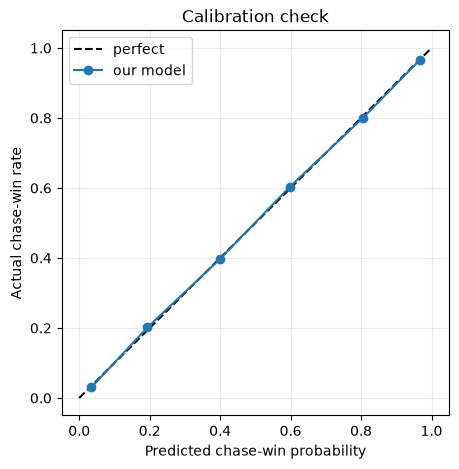

In [39]:
# Step 39 ---------------------------------------------------------------------------------
def fit_logistic(X, y, steps=25):
    """Fit a logistic regression with Newton's method. Returns the weights."""
    X = np.column_stack([np.ones(len(X)), X])           # add an intercept column
    w = np.zeros(X.shape[1])
    for _ in range(steps):
        p = 1 / (1 + np.exp(-X @ w))                    # predicted probability
        weight = p * (1 - p) + 1e-9
        hessian = X.T @ (X * weight[:, None]) + 1e-6 * np.eye(len(w))
        w += np.linalg.solve(hessian, X.T @ (y - p))    # Newton update
    return w

def chase_features(d):
    rr = d["required_rate"].clip(0, 20)                 # cap silly values
    wih = d["wickets_in_hand"] / 10
    bl = d["balls_left"] / 120
    return np.column_stack([rr, wih, bl, rr * wih, rr * bl, wih * bl, np.log1p(d["runs_needed"])])

X = chase_features(chase)
x_mean, x_std = X.mean(axis=0), X.std(axis=0)
weights = fit_logistic((X - x_mean) / x_std, chase["chase_won"].to_numpy())

def win_probability(d):
    Z = (chase_features(d) - x_mean) / x_std
    return 1 / (1 + np.exp(-(np.column_stack([np.ones(len(Z)), Z]) @ weights)))

chase["win_prob"] = win_probability(chase)

# calibration: predicted vs actual win rate
chase["prob_band"] = pd.cut(chase["win_prob"], [0, .1, .3, .5, .7, .9, 1])
calibration = chase.groupby("prob_band", observed=True).agg(
    balls=("win_prob", "size"), predicted=("win_prob", "mean"), actual=("chase_won", "mean"))
display(calibration)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "k--", label="perfect")
ax.plot(calibration["predicted"], calibration["actual"], "o-", label="our model")
ax.set_xlabel("Predicted chase-win probability"); ax.set_ylabel("Actual chase-win rate")
ax.set_title("Calibration check"); ax.legend(); ax.grid(alpha=.25)
plt.show()


## Step 40: Turn win probability into a Pressure Index

Two ideas combine:

1. **Closeness** = `1 - |2p - 1|`. It is 1 when the chase is a coin flip (p = 0.5) and 0 when the match is already decided (p near 0 or 1).
2. **Lateness** = share of the innings already bowled. A 50-50 position after 2 overs is not real pressure, because there is lots of time left.

```
Pressure Index = closeness x sqrt(lateness)
```

The square root stops lateness from over-punishing the middle overs. The index lies between 0 and about 0.85; higher means the next ball matters more. We label the top 25% of chase balls as **High** pressure, the bottom 50% as **Normal**, and the rest as **Medium**.


High pressure: Pressure Index >= 0.319 | Normal: <= 0.152
pressure_level
Normal    46301
High      23151
Medium    23149
Name: count, dtype: int64


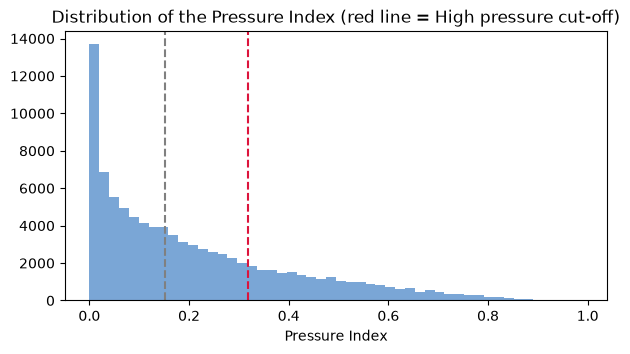

In [40]:
# Step 40 ---------------------------------------------------------------------------------
chase["closeness"] = 1 - (2 * chase["win_prob"] - 1).abs()
chase["lateness"] = 1 - chase["balls_left"] / 120
chase["pressure_index"] = chase["closeness"] * np.sqrt(chase["lateness"])

high_cut = chase["pressure_index"].quantile(0.75)
low_cut = chase["pressure_index"].quantile(0.50)
chase["pressure_level"] = np.where(chase["pressure_index"] >= high_cut, "High",
                            np.where(chase["pressure_index"] <= low_cut, "Normal", "Medium"))

print(f"High pressure: Pressure Index >= {high_cut:.3f} | Normal: <= {low_cut:.3f}")
print(chase["pressure_level"].value_counts())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(chase["pressure_index"], bins=50, color="#7aa6d6")
ax.axvline(low_cut, color="grey", ls="--"); ax.axvline(high_cut, color="crimson", ls="--")
ax.set_title("Distribution of the Pressure Index (red line = High pressure cut-off)")
ax.set_xlabel("Pressure Index"); plt.show()


## Step 41: Does the index really separate pressure from ordinary situations?

The problem statement asks us to **show** this. A good test is the **swing**: how much the win probability actually changes on the next ball. If our index is meaningful, high-pressure balls should swing the match much more than normal balls.

We also describe each level by the situation facts (required rate, wickets in hand, balls left, win probability).


,balls,matches,avg_swing_in_win_prob,avg_win_prob,median_required_rate,avg_wickets_in_hand,avg_balls_left
pressure_level,,,,,,,
Normal,46301,812,0.006,0.469,10.190,6.937,61.164
Medium,23149,688,0.018,0.489,9.188,8.014,76.878
High,23151,529,0.031,0.491,9.750,7.245,59.029


A high-pressure ball swings the win probability 4.8 times as much as a normal ball.


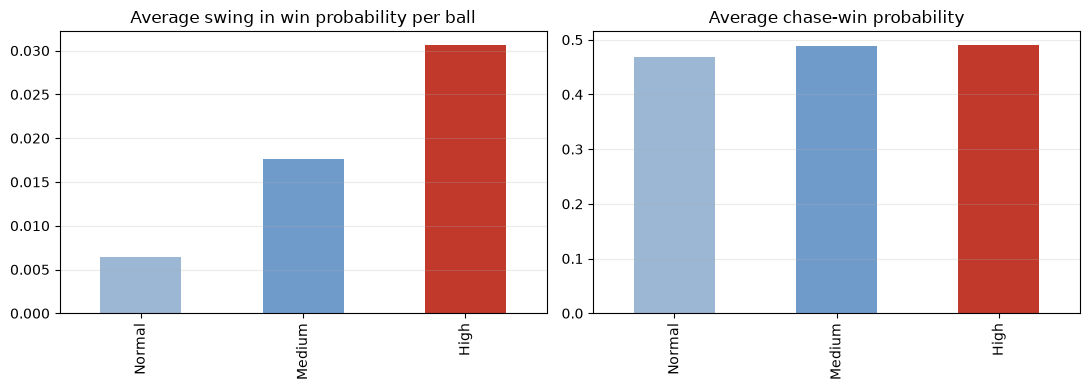

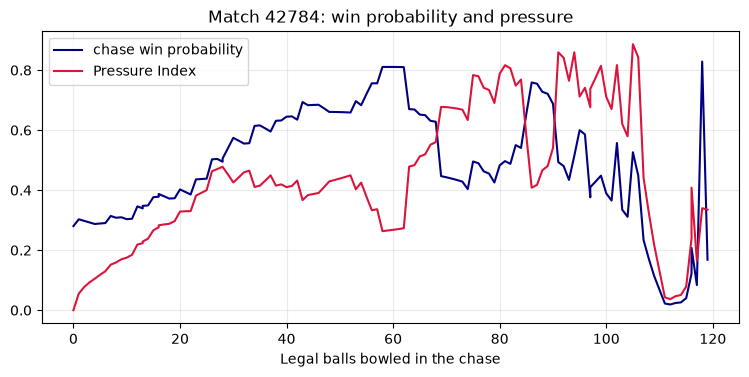

In [41]:
# Step 41 ---------------------------------------------------------------------------------
# swing = absolute change in win probability from this ball to the next ball
chase = chase.sort_values(["match_id", "innings_ball_num"]).copy()
chase["next_prob"] = chase.groupby("match_id")["win_prob"].shift(-1)
last_ball = chase["next_prob"].isna()
chase.loc[last_ball, "next_prob"] = chase.loc[last_ball, "chase_won"]       # after the last ball the result is known
chase["swing"] = (chase["next_prob"] - chase["win_prob"]).abs()

level_table = chase.groupby("pressure_level").agg(
    balls=("swing", "size"),
    matches=("match_id", "nunique"),
    avg_swing_in_win_prob=("swing", "mean"),
    avg_win_prob=("win_prob", "mean"),
    median_required_rate=("required_rate", "median"),
    avg_wickets_in_hand=("wickets_in_hand", "mean"),
    avg_balls_left=("balls_left", "mean"),
).reindex(["Normal", "Medium", "High"])
display(level_table)

ratio = level_table.loc["High", "avg_swing_in_win_prob"] / level_table.loc["Normal", "avg_swing_in_win_prob"]
print(f"A high-pressure ball swings the win probability {ratio:.1f} times as much as a normal ball.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
level_table["avg_swing_in_win_prob"].plot(kind="bar", ax=axes[0], color=["#9bb7d4", "#6f9bcb", "#c0392b"], title="Average swing in win probability per ball")
level_table["avg_win_prob"].plot(kind="bar", ax=axes[1], color=["#9bb7d4", "#6f9bcb", "#c0392b"], title="Average chase-win probability")
for a in axes: a.set_xlabel(""); a.grid(axis="y", alpha=.25)
plt.tight_layout(); plt.show()

# one dramatic chase: win probability and pressure ball by ball
match_swing = chase.groupby("match_id")["swing"].sum().sort_values(ascending=False)
example = chase[chase["match_id"] == match_swing.index[0]]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(example["legal_before"], example["win_prob"], color="navy", label="chase win probability")
ax.plot(example["legal_before"], example["pressure_index"], color="crimson", label="Pressure Index")
ax.set_xlabel("Legal balls bowled in the chase"); ax.set_title(f"Match {match_swing.index[0]}: win probability and pressure"); ax.legend(); ax.grid(alpha=.25)
plt.show()


## Step 42: Measure the value of every ball for the batter and for the bowler

To compare players fairly we ask how much better a ball was than the **league average for that situation** (same league and same over number), because death overs score more than the powerplay and the IPL scores differently from T20Is.

**Batter value of a ball** = runs off the bat, minus a **wicket cost** if the batter was dismissed, minus the league average of that same quantity.

**Bowler value of a ball** = minus the runs charged to the bowler (runs off the bat plus wides and no-balls), plus a **wicket value** if the bowler took a wicket (bowled, caught, LBW, stumped or hit wicket; run-outs are not credited), minus the league average.

A positive value means *better than the average player in that situation*. The wicket cost is a judgement call (about 10 runs here); Step 49 tests how much the ranking depends on it.


In [42]:
# Step 42 ---------------------------------------------------------------------------------
WICKET_COST = 10          # runs a wicket is worth (tested again in Step 49)
BOWLER_WICKETS = ["Caught", "Bowled", "LBW", "Stump", "Hit Wicket"]

pb["charged_runs"] = pb["runs"] + np.where(pb["extras_type"].isin(["wide", "Overstep"]),
                                           pb["extras1_runs"] + pb["extras_2_runs"], 0)
pb["batter_out"] = ((pb["is_wicket"] == 1) & (pb["dismissed_player_id"] == pb["striker_id"])).astype(int)
pb["bowler_wicket"] = ((pb["is_wicket"] == 1) & pb["dismissal_type"].isin(BOWLER_WICKETS)).astype(int)

pb["bat_raw"] = pb["runs"] - WICKET_COST * pb["batter_out"]
pb["bowl_raw"] = -pb["charged_runs"] + WICKET_COST * pb["bowler_wicket"]

# subtract the league average for the same league and over number
for raw, value in [("bat_raw", "bat_value"), ("bowl_raw", "bowl_value")]:
    pb[value] = pb[raw] - pb.groupby(["league", "overid"])[raw].transform("mean")

# bring the pressure level from the chase table (innings 1 and non-rated balls get "Not rated")
level_lookup = chase[["match_id", "innings", "innings_ball_num", "pressure_level"]]
pb = pb.merge(level_lookup, on=["match_id", "innings", "innings_ball_num"], how="left")
pb["pressure_level"] = pb["pressure_level"].fillna("Not rated")

# batters do not face wides, so remove them for the batting table
bat_balls = pb[pb["extras_type"] != "wide"]
print(pb["pressure_level"].value_counts())
display(pb[["striker_name", "bowler_name", "overid", "runs", "bat_value", "bowl_value", "pressure_level"]].head(6))


pressure_level
Not rated    108360
Normal        46301
High          23151
Medium        23149
Name: count, dtype: int64


,striker_name,bowler_name,overid,runs,bat_value,bowl_value,pressure_level
0,Jason Roy,Sheldon Cottrell,1,0,-0.622,0.692,Not rated
1,Jason Roy,Sheldon Cottrell,1,0,-0.622,0.692,Not rated
2,Jason Roy,Sheldon Cottrell,1,0,-0.622,0.692,Not rated
3,Jason Roy,Sheldon Cottrell,1,0,-0.622,0.692,Not rated
4,Jason Roy,Sheldon Cottrell,1,6,5.378,-5.308,Not rated
5,Jason Roy,Sheldon Cottrell,1,0,-10.622,10.692,Not rated


## Step 43: Pressure record versus usual record for each player

For every player we compute, per 100 balls:

* **P (pressure value):** average value on **High** pressure balls
* **U (usual value):** average value on all other balls (first innings and non-high-pressure chase balls). This is the player's *usual level*.

**Why not just rank by P?** A player may face only 150 high-pressure balls, which is a small sample. A lucky or unlucky few overs would dominate the ranking. So we **blend** the two:

```
Expected pressure rating  R = U + w x (P - U),     w = n_pressure / (n_pressure + K)
```

When a player has few pressure balls, `w` is small and `R` stays close to the usual level. As pressure evidence grows, `R` moves towards `P`. `K` controls how much evidence we demand. The next step tests which `K` works best.


In [43]:
# Step 43 ---------------------------------------------------------------------------------
def player_table(df, id_col, name_col, value_col):
    """One row per player: pressure and usual value sums and ball counts."""
    high = df[df["pressure_level"] == "High"]
    usual = df[df["pressure_level"] != "High"]
    p = high.groupby([id_col, name_col])[value_col].agg(P_n="size", P_sum="sum")
    u = usual.groupby([id_col, name_col])[value_col].agg(U_n="size", U_sum="sum")
    table = p.join(u, how="inner").reset_index()
    table["P"] = table["P_sum"] / table["P_n"] * 100               # value per 100 balls under pressure
    table["U"] = table["U_sum"] / (table["U_n"] + 100) * 100       # usual value, lightly shrunk for small samples
    return table

bat_players = player_table(bat_balls, "striker_id", "striker_name", "bat_value")
bowl_players = player_table(pb, "bowler_id", "bowler_name", "bowl_value")
print("Batters with any pressure balls:", len(bat_players), "| bowlers:", len(bowl_players))
display(bat_players.sort_values("P_n", ascending=False).head(5))


Batters with any pressure balls: 505 | bowlers: 436


,striker_id,striker_name,P_n,P_sum,U_n,U_sum,P,U
349,7897,Namboori Tilak Varma,505,128.447,2010,500.158,25.435,23.704
74,1699,Suryakumar Yadav,367,176.243,2392,901.354,48.023,36.170
163,3647,Shreyas Iyer,318,126.784,1547,324.328,39.869,19.692
191,4117,Ishan Kishan,271,72.994,2140,227.099,26.935,10.138
274,6288,Shubman Gill,270,76.851,2441,574.771,28.463,22.620


## Step 44: Choose the blending strength `K` using evidence

We test the idea on **unseen matches**. Matches are split into two halves (odd and even match IDs). For each player we build a rating from half A and see how well it predicts the player's pressure performance in half B. We compare:

* **raw pressure** only (K = 0, no shrinkage)
* **usual** record only
* **blends** with different `K`

A higher rank correlation (Spearman) means better prediction of pressure performance on matches the rating never saw.


In [44]:
# Step 44 ---------------------------------------------------------------------------------
def half_table(df, id_col, name_col, value_col, half):
    return player_table(df[df["match_id"] % 2 == half], id_col, name_col, value_col).set_index(id_col)

def prediction_test(df, id_col, name_col, value_col, K_list=(0, 100, 300, 600, 1000)):
    a = half_table(df, id_col, name_col, value_col, 0)
    b = half_table(df, id_col, name_col, value_col, 1)
    both = a.join(b, lsuffix="_a", rsuffix="_b", how="inner")
    both = both[(both["P_n_a"] >= 40) & (both["P_n_b"] >= 40) & (both["U_n_a"] >= 150)]
    truth = both["P_b"]                                           # pressure value in the unseen half
    rows = [{"rating used": "raw pressure only", "rank correlation with unseen matches": both["P_a"].corr(truth, method="spearman")},
            {"rating used": "usual record only", "rank correlation with unseen matches": both["U_a"].corr(truth, method="spearman")}]
    for K in K_list[1:]:
        w = both["P_n_a"] / (both["P_n_a"] + K)
        blended = both["U_a"] + w * (both["P_a"] - both["U_a"])
        rows.append({"rating used": f"blend with K = {K}", "rank correlation with unseen matches": blended.corr(truth, method="spearman")})
    return len(both), pd.DataFrame(rows)

n_bat, bat_test = prediction_test(bat_balls, "striker_id", "striker_name", "bat_value")
n_bowl, bowl_test = prediction_test(pb, "bowler_id", "bowler_name", "bowl_value")
print(f"BATTERS ({n_bat} players in both halves)"); display(bat_test)
print(f"BOWLERS ({n_bowl} players in both halves)"); display(bowl_test)
print("Reading: raw pressure numbers are noisy. Blending with the usual record predicts unseen pressure matches better.")


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_9568\3575262515.py:8: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  both = a.join(b, lsuffix="_a", rsuffix="_b", how="inner")


BATTERS (60 players in both halves)


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_9568\3575262515.py:8: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  both = a.join(b, lsuffix="_a", rsuffix="_b", how="inner")


,rating used,rank correlation with unseen matches
0,raw pressure only,0.158
1,usual record only,0.129
2,blend with K = 100,0.220
3,blend with K = 300,0.190
4,blend with K = 600,0.174
5,blend with K = 1000,0.168


BOWLERS (65 players in both halves)


,rating used,rank correlation with unseen matches
0,raw pressure only,0.248
1,usual record only,0.260
2,blend with K = 100,0.313
3,blend with K = 300,0.322
4,blend with K = 600,0.292
5,blend with K = 1000,0.271


Reading: raw pressure numbers are noisy. Blending with the usual record predicts unseen pressure matches better.


## Step 45: Consistency, eligibility and the final rating

**Consistency.** The problem asks for players who deliver *consistently*. For each player we look at every match in which they faced (or bowled) at least 6 high-pressure balls and count the share of matches in which their pressure value was **zero or better** (the *hit rate*). We smooth it as `(hits + 2) / (matches + 4)` so a player with 2 matches and 2 hits does not get 100%.

**Eligibility (fair comparison).** A player must have at least **100 high-pressure balls**, at least **8 pressure matches** and at least **150 usual balls**. This removes players whose record is mostly luck.

**Final score** = `0.75 x z(R) + 0.25 x z(hit rate)`, where `z` standardises each measure (mean 0, standard deviation 1) among eligible players.


In [45]:
# Step 45 ---------------------------------------------------------------------------------
K = 300                 # blending strength: the best compromise for batters and bowlers in Step 44
W_CONSISTENCY = 0.25    # weight of the consistency component
MIN_PRESSURE_BALLS, MIN_PRESSURE_MATCHES, MIN_USUAL_BALLS = 100, 8, 150

def zscore(s):
    return (s - s.mean()) / s.std()

def rate_players(df, id_col, name_col, value_col, K=K, w_cons=W_CONSISTENCY,
                 min_p=MIN_PRESSURE_BALLS, min_m=MIN_PRESSURE_MATCHES, min_u=MIN_USUAL_BALLS):
    table = player_table(df, id_col, name_col, value_col)

    # blended expected pressure rating R
    w = table["P_n"] / (table["P_n"] + K)
    table["R"] = table["U"] + w * (table["P"] - table["U"])

    # consistency: match-by-match pressure value
    high = df[df["pressure_level"] == "High"]
    per_match = high.groupby([id_col, "match_id"])[value_col].agg(total="sum", balls="size").reset_index()
    per_match = per_match[per_match["balls"] >= 6]
    per_match["good_match"] = (per_match["total"] >= 0).astype(int)
    cons = per_match.groupby(id_col).agg(P_matches=("good_match", "size"), good_matches=("good_match", "sum")).reset_index()
    table = table.merge(cons, on=id_col, how="left")
    table["hit_rate"] = (table["good_matches"] + 2) / (table["P_matches"] + 4)

    # share of pressure balls played in the IPL (context information)
    ipl_share = (high.assign(is_ipl=(high["league"] == "IPL").astype(int))
                     .groupby(id_col)["is_ipl"].mean().rename("IPL_share").reset_index())
    table = table.merge(ipl_share, on=id_col, how="left")

    # eligibility and score
    table = table[(table["P_n"] >= min_p) & (table["P_matches"] >= min_m) & (table["U_n"] >= min_u)].copy()
    table["score"] = (1 - w_cons) * zscore(table["R"]) + w_cons * zscore(table["hit_rate"])
    return table.sort_values("score", ascending=False).reset_index(drop=True)

batters = rate_players(bat_balls, "striker_id", "striker_name", "bat_value")
bowlers = rate_players(pb, "bowler_id", "bowler_name", "bowl_value")
print("Eligible batters:", len(batters), "| eligible bowlers:", len(bowlers))


Eligible batters: 48 | eligible bowlers: 70


## Step 46: The two top-10 lists

Columns: `P_n` = high-pressure balls faced or bowled, `P_matches` = pressure matches, `P` = value per 100 balls under pressure, `U` = usual value per 100 balls, `R` = blended rating, `hit_rate` = consistency, `IPL_share` = share of pressure balls in the IPL (the rest are T20Is).


In [46]:
# Step 46 ---------------------------------------------------------------------------------
show_cols = ["player_id", "player", "P_n", "P_matches", "P", "U", "R", "hit_rate", "IPL_share", "score"]

top_batters = batters.head(10).rename(columns={"striker_id": "player_id", "striker_name": "player"})[show_cols].copy()
top_bowlers = bowlers.head(10).rename(columns={"bowler_id": "player_id", "bowler_name": "player"})[show_cols].copy()
top_batters.insert(0, "rank", range(1, 11)); top_bowlers.insert(0, "rank", range(1, 11))

print("TOP 10 BATTERS UNDER PRESSURE")
display(top_batters.round(2))
print("TOP 10 BOWLERS UNDER PRESSURE")
display(top_bowlers.round(2))


TOP 10 BATTERS UNDER PRESSURE


,rank,player_id,player,P_n,P_matches,P,U,R,hit_rate,IPL_share,score
0,1,1699,Suryakumar Yadav,367,21.000,48.020,36.170,42.690,0.760,0.650,2.040
1,2,4260,Heinrich Klaasen,169,10.000,36.240,34.340,35.020,0.710,0.740,1.470
2,3,813,Jos Buttler,193,12.000,22.990,29.940,27.220,0.880,0.670,1.430
3,4,6281,Abhishek Sharma,192,15.000,24.890,46.690,38.180,0.580,0.820,1.300
4,5,6396,Tim David,213,16.000,14.080,49.240,34.640,0.650,0.450,1.280
5,6,3024,Mohammad Rizwan,211,9.000,45.220,22.660,31.980,0.690,0.000,1.230
6,7,5553,Phil Salt,126,9.000,31.640,39.350,37.070,0.540,0.400,1.130
7,8,5939,Cameron Green,191,13.000,40.210,21.170,28.580,0.710,0.370,1.070
8,9,3647,Shreyas Iyer,318,17.000,39.870,19.690,30.070,0.670,0.810,1.050
9,10,20702,Tristan Stubbs,181,9.000,9.890,26.790,20.430,0.770,0.650,0.750


TOP 10 BOWLERS UNDER PRESSURE


,rank,player_id,player,P_n,P_matches,P,U,R,hit_rate,IPL_share,score
0,1,34485,Sufiyan Muqeem,106,9.000,62.740,38.690,44.970,0.690,0.000,2.210
1,2,6450,Mujeeb Ur Rahman,125,10.000,81.830,14.080,34.010,0.790,0.000,1.910
2,3,2490,Mohammad Nawaz,205,16.000,58.530,19.040,35.070,0.650,0.000,1.700
3,4,4219,Krunal Pandya,248,15.000,69.240,0.120,31.400,0.630,1.000,1.510
4,5,5979,Abrar Ahmed,135,9.000,36.540,26.220,29.430,0.620,0.000,1.400
5,6,8661,Matheesha Pathirana,152,12.000,36.650,19.020,24.950,0.690,0.750,1.340
6,7,830,Josh Hazlewood,175,14.000,41.690,20.300,28.180,0.610,0.710,1.330
7,8,781,Sunil Narine,228,17.000,25.330,24.710,24.980,0.670,1.000,1.300
8,9,4722,Rashid Khan,368,24.000,34.230,22.020,28.740,0.570,0.540,1.280
9,10,4692,Lockie Ferguson,112,10.000,109.130,-7.480,24.220,0.640,0.630,1.220


## Step 47: Evidence charts for the report

*Left:* final score of each top-10 player. *Right:* usual value (x) against pressure value (y) for **all eligible players**. Points **above the diagonal** play better under pressure than usual; points below play worse. Top-10 players are labelled.


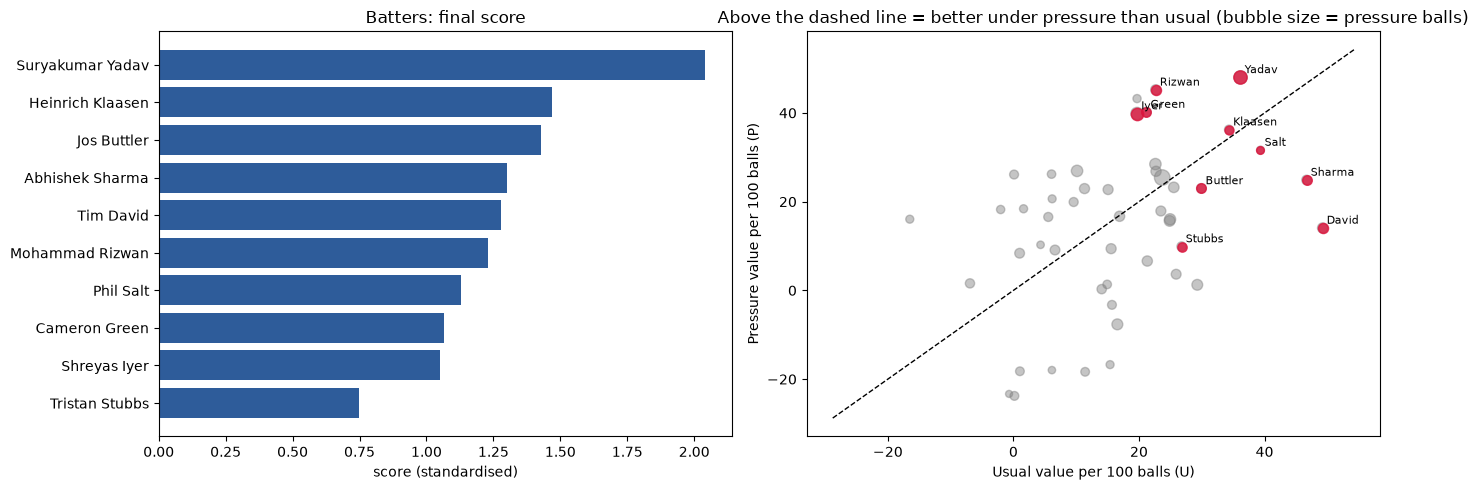

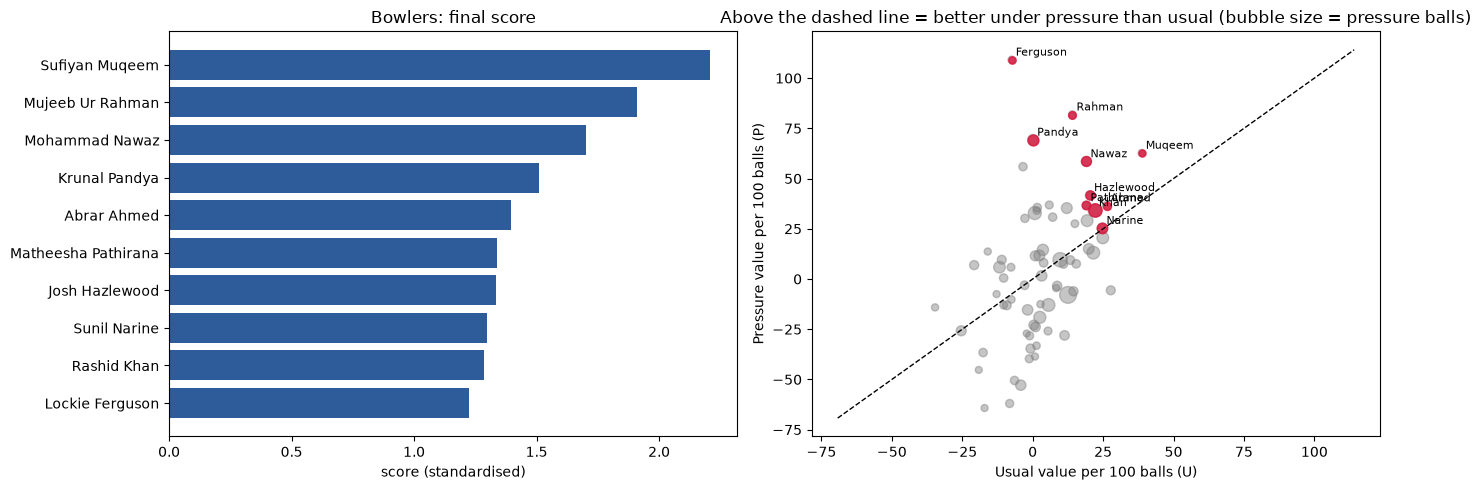

In [47]:
# Step 47 ---------------------------------------------------------------------------------
def evidence_chart(top, table, name_col, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].barh(top["player"][::-1], top["score"][::-1], color="#2e5c9a")
    axes[0].set_title(f"{title}: final score"); axes[0].set_xlabel("score (standardised)")

    axes[1].scatter(table["U"], table["P"], s=table["P_n"] / 4, alpha=.45, color="grey")
    lim = [min(table["U"].min(), table["P"].min()) - 5, max(table["U"].max(), table["P"].max()) + 5]
    axes[1].plot(lim, lim, "k--", lw=1)
    for _, r in table.head(10).iterrows():
        axes[1].scatter(r["U"], r["P"], s=r["P_n"] / 4, color="crimson", alpha=.8)
        axes[1].annotate(r[name_col].split()[-1], (r["U"], r["P"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    axes[1].set_xlabel("Usual value per 100 balls (U)"); axes[1].set_ylabel("Pressure value per 100 balls (P)")
    axes[1].set_title("Above the dashed line = better under pressure than usual (bubble size = pressure balls)")
    plt.tight_layout(); plt.show()

evidence_chart(top_batters, batters, "striker_name", "Batters")
evidence_chart(top_bowlers, bowlers, "bowler_name", "Bowlers")


## Step 48: Reliability check 1, split-half consistency

If a pressure rating measures something real, a player's pressure value in the odd-numbered matches should resemble their value in the even-numbered matches. This table reports that correlation for the **raw** pressure value and for the **usual** value.

A low correlation is not a failure of the code. It is an honest finding: **pressure performance is noisy** in T20 because each player has few pressure balls. It is the reason the rating uses blending and eligibility rules, and it belongs in the limitations section of the report.


In [48]:
# Step 48 ---------------------------------------------------------------------------------
def split_half(df, id_col, name_col, value_col, min_balls=50):
    a = half_table(df, id_col, name_col, value_col, 0)
    b = half_table(df, id_col, name_col, value_col, 1)
    both = a.join(b, lsuffix="_a", rsuffix="_b", how="inner")
    p = both[(both["P_n_a"] >= min_balls) & (both["P_n_b"] >= min_balls)]
    u = both[(both["U_n_a"] >= 150) & (both["U_n_b"] >= 150)]
    return {"players (pressure)": len(p), "pressure value: odd vs even matches": p["P_a"].corr(p["P_b"], method="spearman"),
            "players (usual)": len(u), "usual value: odd vs even matches": u["U_a"].corr(u["U_b"], method="spearman")}

reliability = pd.DataFrame({"batters": split_half(bat_balls, "striker_id", "striker_name", "bat_value"),
                            "bowlers": split_half(pb, "bowler_id", "bowler_name", "bowl_value")})
display(reliability)


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_9568\3946666933.py:5: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  both = a.join(b, lsuffix="_a", rsuffix="_b", how="inner")
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_9568\3946666933.py:5: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  both = a.join(b, lsuffix="_a", rsuffix="_b", how="inner")


,batters,bowlers
players (pressure),46.000,53.000
pressure value: odd vs even matches,-0.073,0.271
players (usual),141.000,157.000
usual value: odd vs even matches,0.406,0.128


## Step 49: Reliability check 2, how sensitive are the top 10 lists?

We change one design choice at a time and count how many of the original top-10 players stay in the top 10. A high overlap means the ranking does not depend on one arbitrary choice. (The wicket cost needs the ball values rebuilt, so it is tested with a small helper.)


In [49]:
# Step 49 ---------------------------------------------------------------------------------
def top10_names(table, name_col):
    return set(table.head(10)[name_col])

base_bat, base_bowl = top10_names(batters, "striker_name"), top10_names(bowlers, "bowler_name")
tests = {
    "more shrinkage (K = 600)": dict(K=600),
    "less shrinkage (K = 150)": dict(K=150),
    "no consistency component": dict(w_cons=0),
    "consistency weight 40%": dict(w_cons=0.40),
    "stricter eligibility (150 pressure balls)": dict(min_p=150),
}
rows = []
for label, kwargs in tests.items():
    b1 = rate_players(bat_balls, "striker_id", "striker_name", "bat_value", **kwargs)
    b2 = rate_players(pb, "bowler_id", "bowler_name", "bowl_value", **kwargs)
    rows.append({"change": label,
                 "batters still in top 10": len(base_bat & top10_names(b1, "striker_name")),
                 "bowlers still in top 10": len(base_bowl & top10_names(b2, "bowler_name"))})

# wicket cost test: rebuild the two value columns with another cost
def rebuild_with_cost(cost):
    tmp = pb.copy()
    tmp["bat_raw"] = tmp["runs"] - cost * tmp["batter_out"]
    tmp["bowl_raw"] = -tmp["charged_runs"] + cost * tmp["bowler_wicket"]
    for raw, value in [("bat_raw", "bat_value"), ("bowl_raw", "bowl_value")]:
        tmp[value] = tmp[raw] - tmp.groupby(["league", "overid"])[raw].transform("mean")
    return tmp

for cost in [5, 15]:
    tmp = rebuild_with_cost(cost)
    b1 = rate_players(tmp[tmp["extras_type"] != "wide"], "striker_id", "striker_name", "bat_value")
    b2 = rate_players(tmp, "bowler_id", "bowler_name", "bowl_value")
    rows.append({"change": f"wicket cost = {cost} runs",
                 "batters still in top 10": len(base_bat & top10_names(b1, "striker_name")),
                 "bowlers still in top 10": len(base_bowl & top10_names(b2, "bowler_name"))})
sensitivity = pd.DataFrame(rows)
display(sensitivity)
print("Reading: names that drop out under a stricter rule are usually the ones with the smallest pressure samples,")
print("so their positions are the least certain. Mention this when you explain ranks 7 to 10.")


,change,batters still in top 10,bowlers still in top 10
0,more shrinkage (K = 600),10,9
1,less shrinkage (K = 150),9,9
2,no consistency component,9,10
3,consistency weight 40%,10,9
4,stricter eligibility (150 pressure balls),9,6
5,wicket cost = 5 runs,8,8
6,wicket cost = 15 runs,7,8


Reading: names that drop out under a stricter rule are usually the ones with the smallest pressure samples,
so their positions are the least certain. Mention this when you explain ranks 7 to 10.


## Step 50: IPL versus T20I

IPL and T20I conditions differ (opposition quality, ground sizes, scoring rates). We handled this in two ways:

1. every ball is compared with the league average **of its own league and over number** (Step 42);
2. the `IPL_share` column shows how much of each top-10 player's pressure sample comes from the IPL.

The table below shows how much pressure data each league contributes.


In [50]:
# Step 50 ---------------------------------------------------------------------------------
league_summary = chase.groupby("league").agg(
    chase_matches=("match_id", "nunique"),
    chase_balls=("match_id", "size"),
    high_pressure_balls=("pressure_level", lambda s: (s == "High").sum()),
    avg_required_rate=("required_rate", "mean"),
)
league_summary["high_pressure_share"] = league_summary["high_pressure_balls"] / league_summary["chase_balls"]
display(league_summary)

print("Top-10 batters, share of pressure balls in the IPL:", top_batters["IPL_share"].round(2).tolist())
print("Top-10 bowlers, share of pressure balls in the IPL:", top_bowlers["IPL_share"].round(2).tolist())


,chase_matches,chase_balls,high_pressure_balls,avg_required_rate,high_pressure_share
league,,,,,
IPL,355,41319,10690,11.804,0.259
Other T20,28,3046,631,11.537,0.207
T20I,429,48236,11830,11.128,0.245


Top-10 batters, share of pressure balls in the IPL: [0.65, 0.74, 0.67, 0.82, 0.45, 0.0, 0.4, 0.37, 0.81, 0.65]
Top-10 bowlers, share of pressure balls in the IPL: [0.0, 0.0, 0.0, 1.0, 0.0, 0.75, 0.71, 1.0, 0.54, 0.63]


## Step 51: Limitations and ideas to improve the model

**Known limits (state these in the report):**

1. **Chase-only pressure.** Pressure is defined where a target exists. First-innings pressure (collapses, par scores) is not rated; first-innings balls only help to estimate each player's *usual* level.
2. **Small samples.** Most players have 100 to 400 high-pressure balls, so pressure numbers are noisy (see Step 48). The blending and eligibility rules reduce, not remove, this.
3. **No opposition adjustment.** A batter facing a weaker T20I attack is treated like one facing a top IPL bowler.
4. **Wicket cost and weights are judgement calls.** Step 49 shows they change few names, but they are not data-proven.
5. **Rain-affected, no-result and super-over matches are excluded** from the win-probability model.
6. **Data issues.** `bowl_speed` is unreliable (not used); batting-order rows in `playing_eleven` repeat for some players (not used); a small number of names map to more than one ID (use `player_id` when matching to the dropdown).

**Ideas to improve:**

* add a first-innings pressure measure (runs behind par, wickets lost early);
* use ball-by-ball `batting_order` and `is_impact` flags for role context;
* adjust for opposition strength with a simple team rating;
* fit the win-probability model with a library such as scikit-learn and compare;
* treat batter vs bowler type matchups (`pace_or_spin`, `batting_type`) as extra context.


## Step 52: Save the outputs

The final tables are written to `cricket_analysis_outputs/` next to the Part A files.


In [51]:
# Step 52 ---------------------------------------------------------------------------------
exports_b = {
    "B_top10_batters_under_pressure.csv": top_batters,
    "B_top10_bowlers_under_pressure.csv": top_bowlers,
    "B_batter_pressure_ratings_all_eligible.csv": batters,
    "B_bowler_pressure_ratings_all_eligible.csv": bowlers,
    "B_pressure_level_validation.csv": level_table.reset_index(),
    "B_win_probability_calibration.csv": calibration.reset_index().astype({"prob_band": str}),
    "B_reliability_split_half.csv": reliability.reset_index().rename(columns={"index": "measure"}),
    "B_sensitivity_of_top10.csv": sensitivity,
    "B_league_summary.csv": league_summary.reset_index(),
}
for filename, table in exports_b.items():
    table.to_csv(OUTPUT_DIR / filename, index=False)
print("Saved", len(exports_b), "Part B files to", OUTPUT_DIR)
for filename in exports_b: print(" -", filename)


Saved 9 Part B files to C:\Users\LENOVO\OneDrive\Desktop\RR\Data Pack\cricket_analysis_outputs
 - B_top10_batters_under_pressure.csv
 - B_top10_bowlers_under_pressure.csv
 - B_batter_pressure_ratings_all_eligible.csv
 - B_bowler_pressure_ratings_all_eligible.csv
 - B_pressure_level_validation.csv
 - B_win_probability_calibration.csv
 - B_reliability_split_half.csv
 - B_sensitivity_of_top10.csv
 - B_league_summary.csv


---
## Checklist before you submit

1. **Rankings:** copy the `player` order from Step 46 into the Unstop dropdowns. If a name is ambiguous, use `player_id` and the `competition_team_player_mapping` table to confirm.
2. **Report sections** (the problem statement asks for five):
   * *Pressure definition*: Steps 39 to 41 (win probability, closeness x lateness, validation by swing)
   * *Performance measurement*: Steps 42 to 45 (ball value, usual record, blending, consistency)
   * *Fair comparisons*: eligibility rules, league averages by IPL / T20I, Step 50
   * *Evidence for the top 10*: Steps 46 and 47
   * *Reliability and limitations*: Steps 48, 49 and 51
3. Your rankings must match the tables in your report. Rerun the notebook if you change any setting.
4. Write the method in your own words; the notebook is your evidence, not the report itself.
